# Transient Detection with the Armstrong Blood-Rheology Data

## Paper-based model, signal-processing comparison, and controlled validation

This notebook preserves the original paper-based model and data-parsing approach while rebuilding the validation around the study’s central question: **does a method locate a known event time, or does it only resemble a model output?**

The experimental workbooks contain Armstrong blood-rheology measurements. They do not contain independently labelled clot or gel times. The synthetic benchmark therefore provides the primary timing ground truth, while the real measurements are used for sampling-quality checks and exploratory response plots. A model-derived structure trace, $\lambda(t)$, is treated as a secondary model-comparison signal, never as experimental event truth.

The equations implemented below are from *A simple approach for adding thixotropy to an elasto-visco-plastic rheological model to facilitate structural interrogation of human blood* (2021), especially Equations 11, 13, and 16 and the parameter table used in the original notebook. The model is a rheological structure model; it is not a clot-time model.

## Analysis questions and decisions

The following decisions are applied throughout the notebook. They are analysis safeguards, not claims that a clinical acceptance threshold has been established.

| Analysis question | Concrete response in this notebook |
|---|---|
| Resampling may invent information | Measuring interval irregularity and long gaps first; interpolating only between nearby observations; refusing unsupported records instead of expanding them to an arbitrary 50 Hz grid. |
| Early transient may be excluded | Defining a known synthetic command time with pre-event samples; using duration-based edge guards; checking that the known event remains inside each method’s searchable support. |
| Methods may not be comparable | Reusing the same trial, observed samples, preprocessing, physical frequency band, and event rule; reporting each method’s actual time/frequency resolution and boundary support. |
| fCWT may only correlate with model λ(t) | Using known synthetic command times for the primary timing score; reporting correlation with λ(t) as secondary shape agreement only. |
| Repeated experiments are paired | Comparing method scores within each synthetic scenario using Friedman, then paired Wilcoxon tests with Holm correction; treating replicates as repeated trials within scenario. |

In [1]:
from pathlib import Path
import os
from IPython.display import display

NOTEBOOK_DIRECTORY = Path("/Users/riamishra/Desktop/Haemograph_Project/02_Synthetic_Benchmark/01_Model_Prototype")
RESULTS_DIRECTORY = Path(os.environ.get("FRESH_CODE_V2_RESULTS_DIRECTORY", str(NOTEBOOK_DIRECTORY / "fresh_code_v2_results")))
CACHE_DIRECTORY = Path(os.environ.get("FRESH_CODE_V2_CACHE_DIRECTORY", str(Path.cwd() / ".fresh_code_v2_cache")))
RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)
CACHE_DIRECTORY.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("NUMBA_CACHE_DIR", str(CACHE_DIRECTORY / "numba"))
os.environ.setdefault("MPLCONFIGDIR", str(CACHE_DIRECTORY / "matplotlib"))

def load_fcwt_module():
    """Loading fCWT and resolving an existing macOS OpenMP dependency if needed."""
    import importlib
    try:
        return importlib.import_module("fcwt")
    except ImportError as import_error:
        if "_omp_" not in str(import_error) or os.name != "posix":
            raise
        import ctypes
        import importlib.util
        torch_specification = importlib.util.find_spec("torch")
        if torch_specification is None or not torch_specification.submodule_search_locations:
            raise import_error
        library_path = Path(torch_specification.submodule_search_locations[0]) / "lib" / "libomp.dylib"
        if not library_path.is_file():
            raise import_error
        ctypes.CDLL(str(library_path), mode=ctypes.RTLD_GLOBAL)
        return importlib.import_module("fcwt")


#### Cell 1: Environment Diagnostic

In [2]:
import importlib
import sys

def check_package(import_name, pip_name=None, purpose=""):
    """
    Checking whether a package is importable, and reporting its version.

    Returning True if the package is available, False otherwise, so the
    summary at the bottom of this cell can flag exactly what still needs
    installing before we move on.
    """
    if pip_name is None:
        pip_name = import_name

    try:
        module_object = load_fcwt_module() if import_name == "fcwt" else importlib.import_module(import_name)
        version_number = getattr(module_object, "__version__", "version unknown")
        print(f"  [OK]      {import_name:<15} version {version_number:<12} - {purpose}")
        return True
    except ImportError as exception_message:
        print(f"  [MISSING] {import_name:<15} {'':<20} - {purpose}")
        print(f"            install with: pip install {pip_name}")
        return False


print("Python version:", sys.version.split()[0])
print()

print("CORE SCIENTIFIC STACK")
print("-" * 70)
package_status = {}
package_status["numpy"]      = check_package("numpy", purpose="arrays and numerical operations")
package_status["pandas"]     = check_package("pandas", purpose="reading Excel files, tables")
package_status["scipy"]      = check_package("scipy", purpose="ODE solving, statistics, signal processing")
package_status["matplotlib"] = check_package("matplotlib", purpose="static publication-quality figures")
print()

print("SYMBOLIC MATH (for verifying the paper's equations before coding them)")
print("-" * 70)
package_status["sympy"] = check_package("sympy", purpose="symbolic equation definition and verification")
print()

print("WAVELET AND SIGNAL PROCESSING")
print("-" * 70)
package_status["pywt"]       = check_package("pywt", pip_name="PyWavelets", purpose="CWT and DWT, most wavelet families")
package_status["ssqueezepy"] = check_package("ssqueezepy", purpose="Morse wavelet for CWT")
package_status["fcwt"]       = check_package("fcwt", purpose="Fast Continuous Wavelet Transform")
print()


Python version: 3.12.1

CORE SCIENTIFIC STACK
----------------------------------------------------------------------
  [OK]      numpy           version 2.5.4        - arrays and numerical operations


  [OK]      pandas          version 3.0.6        - reading Excel files, tables
  [OK]      scipy           version 1.18.1       - ODE solving, statistics, signal processing
  [OK]      matplotlib      version 3.11.2       - static publication-quality figures

SYMBOLIC MATH (for verifying the paper's equations before coding them)
----------------------------------------------------------------------


  [OK]      sympy           version 1.14.0       - symbolic equation definition and verification

WAVELET AND SIGNAL PROCESSING
----------------------------------------------------------------------
  [OK]      pywt            version 1.8.0        - CWT and DWT, most wavelet families


  [OK]      ssqueezepy      version 0.6.6        - Morse wavelet for CWT
  [OK]      fcwt            version version unknown - Fast Continuous Wavelet Transform



#### Continuing the calculation


In [3]:
print("INTERACTIVE AND DYNAMIC VISUALISATION")
print("-" * 70)
package_status["ipywidgets"] = check_package("ipywidgets", purpose="sliders and controls for live parameter exploration")
package_status["plotly"]     = check_package("plotly", purpose="interactive charts that update without flickering")
print()

print("=" * 70)

required_package_names = ["numpy", "pandas", "scipy", "matplotlib", "pywt"]
required_missing_packages = []
for package_name in required_package_names:
    if not package_status.get(package_name):
        required_missing_packages.append(package_name)

package_status["ruptures"] = check_package("ruptures", purpose="optional PELT changepoint baseline")

optional_package_names = ["sympy", "ssqueezepy", "fcwt", "ipywidgets", "plotly", "ruptures"]
optional_missing_packages = []
for package_name in optional_package_names:
    if not package_status.get(package_name):
        optional_missing_packages.append(package_name)

if len(required_missing_packages) > 0:
    print("ACTION NEEDED: install the required packages listed above before continuing.")
else:
    print("All required packages are available.")

if len(optional_missing_packages) > 0:
    print("Optional packages missing:", ", ".join(optional_missing_packages))
    print("The notebook will still run without these; affected features will be")
    print("clearly flagged and skipped rather than causing an error.")
else:
    print("All optional packages are also available. Full functionality enabled.")


INTERACTIVE AND DYNAMIC VISUALISATION
----------------------------------------------------------------------
  [OK]      ipywidgets      version 8.1.9        - sliders and controls for live parameter exploration
  [OK]      plotly          version 7.1.0        - interactive charts that update without flickering

  [OK]      ruptures        version v1.1.10      - optional PELT changepoint baseline
All required packages are available.
All optional packages are also available. Full functionality enabled.


#### Cell 2: Configuration and Visual Theme

In [4]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


DATA_DIRECTORY = "/Users/riamishra/Desktop/Haemograph_Project/01_Active_Blood_Project/01_Data/Haemograph_Rheology"

if not os.path.isdir(DATA_DIRECTORY):
    fallback_directory_candidates = ["./data", "../data", "."]
    for candidate_directory in fallback_directory_candidates:
        candidate_has_workbooks = glob.glob(os.path.join(candidate_directory, "data*.xlsx"))
        if os.path.isdir(candidate_directory) and len(candidate_has_workbooks) > 0:
            DATA_DIRECTORY = candidate_directory
            break

PRIMARY_DATA_FILE = "data8.xlsx"

PAPER_PARAMETERS_DONOR3 = {
    "sigma_y0":       0.0034,
    "eta_infinity":   0.0028,
    "eta_structural": 0.019,
    "G_elastic":      0.29,
    "G_rouleaux":     0.14,
    "tr1":            0.77,
    "tr2":            0.34,
    "k_lambda":       0.88,
    "k_lambda_v2":    0.67,
    "consistency_k":  0.0117,
    "power_law_n":    0.774,
    "G_evp_only":     0.45,
}


#### Continuing the calculation


In [5]:
PAPER_PARAMETER_DESCRIPTIONS = {
    "sigma_y0":       ("Yield stress", "Pa", "minimum stress before the material flows at all"),
    "eta_infinity":   ("Infinite-shear viscosity", "Pa s", "viscosity once structure is fully broken down"),
    "eta_structural": ("Structural viscosity", "Pa s", "extra viscosity contributed by the microstructure"),
    "G_elastic":      ("Elastic modulus, version 1", "Pa", "stiffness of the material, ethixo-EVP v1"),
    "G_rouleaux":     ("Elastic modulus of rouleaux, version 2", "Pa", "stiffness of the rouleaux only, ethixo-EVP v2"),
    "tr1":            ("Shear breakdown time scale", "s", "how fast structure is torn apart by shear"),
    "tr2":            ("Shear aggregation time scale", "s^(1/2)", "how fast structure rebuilds from flow-driven collisions"),
    "k_lambda":       ("Brownian build-up rate, version 1", "1/s", "how fast structure reforms at rest"),
    "k_lambda_v2":    ("Brownian build-up rate, version 2", "1/s", "same, for the ethixo-EVP v2 formulation"),
    "consistency_k":  ("Consistency parameter", "Pa s^n", "power-law scaling constant, baseline models only"),
    "power_law_n":    ("Power law index", "dimensionless", "shear thinning below 1, thickening above 1"),
    "G_evp_only":     ("Elastic modulus, EVP-only baseline", "Pa", "stiffness for the no-thixotropy baseline model"),
}

DEFAULT_SYNTHETIC_SAMPLE_RATES_HZ = [10.0, 25.0, 50.0, 100.0]
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

COLOUR_BACKGROUND = "#FFFFFF"
COLOUR_PANEL      = "#F2F6FA"
COLOUR_GRID       = "#C9D4E0"
COLOUR_TEXT       = "#14202E"
COLOUR_MUTED      = "#5A6B7C"

COLOUR_WINNER     = "#00857A"
COLOUR_RUNNERUP   = "#5B2C9F"
COLOUR_BASELINE   = "#D62839"
COLOUR_NEUTRAL    = "#6B7A8F"
COLOUR_ACCENT     = "#E07B00"

METHOD_FAMILY_COLOURS = {
    "fCWT": COLOUR_WINNER,
    "CWT":  COLOUR_RUNNERUP,
    "DWT":  COLOUR_NEUTRAL,
    "STFT": COLOUR_BASELINE,
}


#### Continuing the calculation


In [6]:
plt.rcParams.update({
    "figure.facecolor":   COLOUR_BACKGROUND,
    "axes.facecolor":     COLOUR_BACKGROUND,
    "savefig.facecolor":  COLOUR_BACKGROUND,
    "text.color":         COLOUR_TEXT,
    "axes.edgecolor":     COLOUR_GRID,
    "axes.labelcolor":    COLOUR_TEXT,
    "xtick.color":        COLOUR_MUTED,
    "ytick.color":        COLOUR_MUTED,
    "axes.grid":          True,
    "grid.color":         COLOUR_GRID,
    "grid.linewidth":     0.9,
    "grid.alpha":         0.7,
    "font.size":          12,
    "axes.titlesize":     15,
    "axes.titleweight":   "bold",
    "axes.labelsize":     12,
    "axes.labelweight":   "bold",
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "legend.frameon":     False,
    "figure.figsize":     (13, 6),
    "figure.dpi":         110,
    "savefig.dpi":        200,
})

SCALOGRAM_COLORMAP = LinearSegmentedColormap.from_list(
    "project_scalogram",
    ["#FFFFFF", "#CFE6F5", "#6FB4DC", "#2E76BC", "#2B3E9E", "#5B2C9F", "#38105E"]
)

print("CONFIGURATION")
print("=" * 78)
print("Data directory        :", DATA_DIRECTORY)

workbook_paths_found = sorted(glob.glob(os.path.join(DATA_DIRECTORY, "data*.xlsx")))
print("Workbooks found       :", len(workbook_paths_found))

if len(workbook_paths_found) == 0:
    print()
    print("WARNING: no workbooks matching 'data*.xlsx' were found at that path.")
    print("Update DATA_DIRECTORY at the top of this cell before continuing.")
else:
    primary_file_full_path = os.path.join(DATA_DIRECTORY, PRIMARY_DATA_FILE)
    primary_file_present = os.path.exists(primary_file_full_path)
    print("Primary analysis file :", PRIMARY_DATA_FILE,
          "(found)" if primary_file_present else "(NOT FOUND)")


CONFIGURATION
Data directory        : /Users/riamishra/Desktop/Haemograph_Project/01_Active_Blood_Project/01_Data/Haemograph_Rheology
Workbooks found       : 15
Primary analysis file : data8.xlsx (found)


#### Continuing the calculation


In [7]:
print("Synthetic sample rates :", DEFAULT_SYNTHETIC_SAMPLE_RATES_HZ, "Hz")
print("Random seed           :", RANDOM_SEED, "(fixed, so every run reproduces identically)")
print()

print("PUBLISHED MODEL PARAMETERS, from Table 3 of the paper, Donor 3")
print("=" * 78)
print(f"{'Parameter':<16}{'Value':>10}  {'Units':<14} Meaning")
print("-" * 78)
for parameter_name, parameter_value in PAPER_PARAMETERS_DONOR3.items():
    readable_name, parameter_units, parameter_meaning = PAPER_PARAMETER_DESCRIPTIONS[parameter_name]
    print(f"{parameter_name:<16}{parameter_value:>10}  {parameter_units:<14} {parameter_meaning}")

print()
print("VISUAL THEME")
print("=" * 78)
print("Light theme active. Method families are colour coded consistently:")
for family_name, family_colour in METHOD_FAMILY_COLOURS.items():
    readable_role = {
        "fCWT": "fast CWT implementation",
        "CWT":  "continuous wavelet family",
        "DWT":  "discrete wavelet family",
        "STFT": "short-time Fourier baseline",
    }[family_name]
    print(f"   {family_name:<6} {family_colour}   {readable_role}")


Synthetic sample rates : [10.0, 25.0, 50.0, 100.0] Hz
Random seed           : 42 (fixed, so every run reproduces identically)

PUBLISHED MODEL PARAMETERS, from Table 3 of the paper, Donor 3
Parameter            Value  Units          Meaning
------------------------------------------------------------------------------
sigma_y0            0.0034  Pa             minimum stress before the material flows at all
eta_infinity        0.0028  Pa s           viscosity once structure is fully broken down
eta_structural       0.019  Pa s           extra viscosity contributed by the microstructure
G_elastic             0.29  Pa             stiffness of the material, ethixo-EVP v1
G_rouleaux            0.14  Pa             stiffness of the rouleaux only, ethixo-EVP v2
tr1                   0.77  s              how fast structure is torn apart by shear
tr2                   0.34  s^(1/2)        how fast structure rebuilds from flow-driven collisions
k_lambda              0.88  1/s            how fas

#### Paper equation source

The following symbolic definitions and checks are carried forward from `fresh_code.ipynb`. Source: *A simple approach for adding thixotropy to an elasto-visco-plastic rheological model to facilitate structural interrogation of human blood* (2021), Equations 11, 13, and 16, plus Equation 10 for steady-state stress. The equation numbers refer to the paper’s main text; model parameter values are carried forward from the original notebook’s transcription of its parameter table. These equations describe constitutive stress and an internal structure state. They do not define a clinical gel point or clot time.

In [8]:
import sympy

lambda_symbol      = sympy.Symbol("lambda", positive=True)
sigma_symbol       = sympy.Symbol("sigma", real=True)
gamma_dot_symbol   = sympy.Symbol("gamma_dot", real=True)
gamma_dot_p_symbol = sympy.Symbol("gamma_dot_p", real=True)

sigma_y0_symbol       = sympy.Symbol("sigma_y0", positive=True)
eta_infinity_symbol   = sympy.Symbol("eta_infinity", positive=True)
eta_structural_symbol = sympy.Symbol("eta_ST", positive=True)
G_symbol              = sympy.Symbol("G", positive=True)
tr1_symbol            = sympy.Symbol("tr1", positive=True)
tr2_symbol            = sympy.Symbol("tr2", positive=True)
k_lambda_symbol       = sympy.Symbol("k_lambda", positive=True)
consistency_k_symbol  = sympy.Symbol("k", positive=True)
power_law_n_symbol    = sympy.Symbol("n", positive=True)

print("PAPER EQUATIONS, DEFINED SYMBOLICALLY")
print("=" * 78)
print("Each equation below is written directly from the published paper, then")
print("checked against a known analytical result before any numerical code uses it.")
print()

shear_breakdown_term   = -tr1_symbol * sympy.Abs(gamma_dot_p_symbol) * lambda_symbol
shear_aggregation_term = tr2_symbol * sympy.sqrt(sympy.Abs(gamma_dot_p_symbol)) * (1 - lambda_symbol)
brownian_buildup_term  = (1 - lambda_symbol)

lambda_dot_expression = k_lambda_symbol * (
    shear_breakdown_term + shear_aggregation_term + brownian_buildup_term
)

print("EQUATION 13, structure evolution")
print("-" * 78)
print("  lambda_dot =")
sympy.pprint(lambda_dot_expression, use_unicode=True)
print()
print("  Term 1, shear breakdown      :", shear_breakdown_term)
print("  Term 2, shear aggregation    :", shear_aggregation_term)
print("  Term 3, Brownian build-up    :", brownian_buildup_term)
print()

lambda_ss_paper_expression = (
    (tr2_symbol * sympy.sqrt(sympy.Abs(gamma_dot_symbol)) + 1)
    / (tr1_symbol * sympy.Abs(gamma_dot_symbol)
       + tr2_symbol * sympy.sqrt(sympy.Abs(gamma_dot_symbol)) + 1)
)

print("EQUATION 16, steady-state structure, as printed in the paper")


PAPER EQUATIONS, DEFINED SYMBOLICALLY
Each equation below is written directly from the published paper, then
checked against a known analytical result before any numerical code uses it.

EQUATION 13, structure evolution
------------------------------------------------------------------------------
  lambda_dot =
    ⎛                                     ___________    ⎞
k_λ⋅⎝-λ⋅tr₁⋅│γ_dot_p│ - λ + tr₂⋅(1 - λ)⋅╲╱ │γ_dot_p│  + 1⎠

  Term 1, shear breakdown      : -lambda*tr1*Abs(gamma_dot_p)
  Term 2, shear aggregation    : tr2*(1 - lambda)*sqrt(Abs(gamma_dot_p))
  Term 3, Brownian build-up    : 1 - lambda

EQUATION 16, steady-state structure, as printed in the paper


#### Continuing the calculation


In [9]:
print("-" * 78)
sympy.pprint(lambda_ss_paper_expression, use_unicode=True)
print()

print("VERIFICATION: deriving Equation 16 from Equation 13 independently")
print("-" * 78)
print("Setting lambda_dot = 0 and solving for lambda should reproduce Equation 16.")
print("At steady state the plastic shear rate equals the applied shear rate.")
print()

lambda_dot_at_steady_state = lambda_dot_expression.subs(gamma_dot_p_symbol, gamma_dot_symbol)
solved_lambda_solutions = sympy.solve(sympy.Eq(lambda_dot_at_steady_state, 0), lambda_symbol)

print("  Solutions found:", len(solved_lambda_solutions))
derived_lambda_ss_expression = sympy.simplify(solved_lambda_solutions[0])
print("  Derived expression:")
sympy.pprint(derived_lambda_ss_expression, use_unicode=True)
print()

difference_between_expressions = sympy.simplify(
    derived_lambda_ss_expression - lambda_ss_paper_expression
)

print("  Difference (derived minus paper):", difference_between_expressions)
if difference_between_expressions == 0:
    print("  RESULT: MATCH. Our Equation 13 is consistent with the paper's Equation 16.")
else:
    print("  RESULT: MISMATCH. Investigate before proceeding.")
print()

yield_numerator_v1   = sympy.Abs(sigma_symbol) - lambda_symbol * sigma_y0_symbol
yield_denominator_v1 = (lambda_symbol * eta_structural_symbol + eta_infinity_symbol) * sympy.Abs(sigma_symbol)
plastic_flow_term_v1 = sympy.Max(0, yield_numerator_v1 / yield_denominator_v1)

sigma_dot_expression_v1 = G_symbol * (gamma_dot_symbol - plastic_flow_term_v1 * sigma_symbol)

print("EQUATION 11, constitutive equation, ethixo-EVP version 1")
print("-" * 78)
print("  Paper form:  (1/G) sigma_dot + max(0, (|sigma| - lambda*sigma_y0)")
print("                                     / ((lambda*eta_ST + eta_inf)|sigma|)) * sigma = gamma_dot")
print()
print("  Rearranged for numerical solving, sigma_dot =")
sympy.pprint(sigma_dot_expression_v1, use_unicode=True)
print()


------------------------------------------------------------------------------
             _________           
       tr₂⋅╲╱ │γ_dot│  + 1       
─────────────────────────────────
                    _________    
tr₁⋅│γ_dot│ + tr₂⋅╲╱ │γ_dot│  + 1

VERIFICATION: deriving Equation 16 from Equation 13 independently
------------------------------------------------------------------------------
Setting lambda_dot = 0 and solving for lambda should reproduce Equation 16.
At steady state the plastic shear rate equals the applied shear rate.

  Solutions found: 1
  Derived expression:
             _________           
       tr₂⋅╲╱ │γ_dot│  + 1       
─────────────────────────────────
                    _________    
tr₁⋅│γ_dot│ + tr₂⋅╲╱ │γ_dot│  + 1

  Difference (derived minus paper): 0
  RESULT: MATCH. Our Equation 13 is consistent with the paper's Equation 16.

EQUATION 11, constitutive equation, ethixo-EVP version 1
-----------------------------------------------------------------------

#### Continuing the calculation


In [10]:
steady_state_stress_expression = (
    lambda_symbol * sigma_y0_symbol
    + lambda_symbol * eta_structural_symbol * gamma_dot_symbol
    + eta_infinity_symbol * gamma_dot_symbol
)

print("EQUATION 10, steady-state stress")
print("-" * 78)
sympy.pprint(steady_state_stress_expression, use_unicode=True)
print()

herschel_bulkley_expression = (
    sigma_y0_symbol + consistency_k_symbol * gamma_dot_symbol ** power_law_n_symbol
)

print("EQUATION 2, Herschel-Bulkley, the steady-state starting point")
print("-" * 78)
sympy.pprint(herschel_bulkley_expression, use_unicode=True)
print()

print("CONVERTING TO FAST NUMERICAL FUNCTIONS")
print("=" * 78)

lambda_ss_numerical_function = sympy.lambdify(
    (gamma_dot_symbol, tr1_symbol, tr2_symbol),
    lambda_ss_paper_expression,
    modules="numpy"
)

steady_state_stress_numerical_function = sympy.lambdify(
    (lambda_symbol, gamma_dot_symbol, sigma_y0_symbol, eta_structural_symbol, eta_infinity_symbol),
    steady_state_stress_expression,
    modules="numpy"
)

print("Created lambda_ss_numerical_function(gamma_dot, tr1, tr2)")
print("Created steady_state_stress_numerical_function(lambda, gamma_dot, sigma_y0, eta_ST, eta_inf)")
print()
print("These are generated automatically from the symbolic expressions above,")
print("so the numerical code cannot silently drift from the verified equations.")
print()

print("SANITY CHECKS on the generated functions")
print("-" * 78)

lambda_at_rest = lambda_ss_numerical_function(0.0, PAPER_PARAMETERS_DONOR3["tr1"], PAPER_PARAMETERS_DONOR3["tr2"])
print(f"  lambda at zero shear rate        : {lambda_at_rest:.6f}   (expected 1.0, fully structured)")


EQUATION 10, steady-state stress
------------------------------------------------------------------------------
η_ST⋅γ_dot⋅λ + η_infinity⋅γ_dot + λ⋅σ_y0

EQUATION 2, Herschel-Bulkley, the steady-state starting point
------------------------------------------------------------------------------
     n         
γ_dot ⋅k + σ_y0

CONVERTING TO FAST NUMERICAL FUNCTIONS
Created lambda_ss_numerical_function(gamma_dot, tr1, tr2)
Created steady_state_stress_numerical_function(lambda, gamma_dot, sigma_y0, eta_ST, eta_inf)

These are generated automatically from the symbolic expressions above,
so the numerical code cannot silently drift from the verified equations.

SANITY CHECKS on the generated functions
------------------------------------------------------------------------------
  lambda at zero shear rate        : 1.000000   (expected 1.0, fully structured)


#### Continuing the calculation


In [11]:
lambda_at_high_shear = lambda_ss_numerical_function(1000.0, PAPER_PARAMETERS_DONOR3["tr1"], PAPER_PARAMETERS_DONOR3["tr2"])
print(f"  lambda at shear rate 1000 per s  : {lambda_at_high_shear:.6f}   (expected near 0, broken down)")

lambda_at_moderate = lambda_ss_numerical_function(5.0, PAPER_PARAMETERS_DONOR3["tr1"], PAPER_PARAMETERS_DONOR3["tr2"])
print(f"  lambda at shear rate 5 per s     : {lambda_at_moderate:.6f}   (partial breakdown)")
print()

stress_at_moderate = steady_state_stress_numerical_function(
    lambda_at_moderate, 5.0,
    PAPER_PARAMETERS_DONOR3["sigma_y0"],
    PAPER_PARAMETERS_DONOR3["eta_structural"],
    PAPER_PARAMETERS_DONOR3["eta_infinity"],
)
print(f"  steady-state stress at 5 per s   : {stress_at_moderate:.6f} Pa")
print()

checks_passed = True
if not (0.99 <= lambda_at_rest <= 1.001):
    print("  CHECK FAILED: lambda at rest should be 1.0")
    checks_passed = False
if not (0.0 <= lambda_at_high_shear <= 0.05):
    print("  CHECK FAILED: lambda at very high shear should approach 0")
    checks_passed = False
if not (lambda_at_high_shear < lambda_at_moderate < lambda_at_rest):
    print("  CHECK FAILED: lambda should decrease monotonically with shear rate")
    checks_passed = False

if checks_passed:
    print("  All sanity checks passed. Equations behave as the physics requires.")


  lambda at shear rate 1000 per s  : 0.015033   (expected near 0, broken down)
  lambda at shear rate 5 per s     : 0.313758   (partial breakdown)

  steady-state stress at 5 per s   : 0.044874 Pa

  All sanity checks passed. Equations behave as the physics requires.


#### Loading the raw signal parser

The multiblock workbook parser below is copied from the original notebook’s foundation. It reads the recorded time and stress columns without resampling. The primary worked example remains the `.1 → 5 s⁻¹` step-up in `data8.xlsx`; the broader workbook list is the same five-file set used in the original cross-experiment loop.

In [12]:
def find_nonempty_column_groups(raw_sheet):
    """Grouping exported columns that are separated by blank columns."""
    column_groups = []
    current_group = []
    for column_index in range(raw_sheet.shape[1]):
        if raw_sheet.iloc[:, column_index].isna().all():
            if len(current_group) > 0:
                column_groups.append(current_group)
                current_group = []
        else:
            current_group.append(column_index)
    if len(current_group) > 0:
        column_groups.append(current_group)
    return column_groups


def parse_one_workbook_block(raw_sheet, column_group):
    """Reading one condition label and its recorded numeric columns."""
    available_labels = raw_sheet.iloc[0, column_group].dropna()
    block_label = str(available_labels.iloc[0]).strip() if len(available_labels) else "unlabelled"
    cleaned_headers = []
    for position, column_index in enumerate(column_group):
        header_value = raw_sheet.iloc[1, column_index]
        if pd.isna(header_value):
            cleaned_headers.append("unnamed_column_" + str(position))
        else:
            cleaned_headers.append(str(header_value).strip())
    block_data = raw_sheet.iloc[3:, column_group].copy()
    block_data.columns = cleaned_headers
    block_data = block_data.apply(pd.to_numeric, errors="coerce")
    block_data = block_data.dropna(how="all").reset_index(drop=True)
    return {"label": block_label, "data": block_data, "row_count": len(block_data)}


def parse_multiblock_sheet(file_path, sheet_name):
    """Parsing each side-by-side experiment without creating new observations."""
    raw_sheet = pd.read_excel(file_path, sheet_name=sheet_name, header=None)
    parsed_blocks = []
    for column_group in find_nonempty_column_groups(raw_sheet):
        parsed_blocks.append(parse_one_workbook_block(raw_sheet, column_group))
    return parsed_blocks


#### Extract time series


In [13]:
def extract_time_series(block_dictionary,
                        time_column_candidates=("Step time", "step time", "Time", "time"),
                        value_column_candidates=("Stress", "stress")):
    """
    Pulling a clean (time, stress) pair out of one parsed block.

    Returning None when the block does not contain both a usable time
    column and a usable value column, so calling code can skip it safely
    rather than crashing on unexpected sheet layouts.
    """
    block_frame = block_dictionary["data"]

    time_column_name = None
    for candidate_name in time_column_candidates:
        if candidate_name in block_frame.columns:
            time_column_name = candidate_name
            break

    value_column_name = None
    for candidate_name in value_column_candidates:
        if candidate_name in block_frame.columns:
            value_column_name = candidate_name
            break

    if time_column_name is None or value_column_name is None:
        return None

    time_values   = pd.to_numeric(block_frame[time_column_name], errors="coerce").values
    stress_values = pd.to_numeric(block_frame[value_column_name], errors="coerce").values

    valid_mask = np.isfinite(time_values) & np.isfinite(stress_values)
    time_values   = time_values[valid_mask]
    stress_values = stress_values[valid_mask]

    if len(time_values) < 16:
        return None

    sort_order    = np.argsort(time_values)
    time_values   = time_values[sort_order]
    stress_values = stress_values[sort_order]

    return time_values, stress_values


## 1. Selecting the primary Armstrong measurement

Loading the primary step-up block while retaining the timestamps exactly as recorded. No interpolation is performed in this step.

In [14]:
PRIMARY_DATA_FILE = "data8.xlsx"
PRIMARY_WORKBOOK_PATH = os.path.join(DATA_DIRECTORY, PRIMARY_DATA_FILE)
PRIMARY_STEP_SHEET = "Step Up Step Down"
PRIMARY_STEP_LABEL = ".1-->5(1/s)"

if not os.path.isfile(PRIMARY_WORKBOOK_PATH):
    raise FileNotFoundError(
        "The primary workbook was not found. Update DATA_DIRECTORY in the configuration cell."
    )

primary_step_blocks = parse_multiblock_sheet(PRIMARY_WORKBOOK_PATH, PRIMARY_STEP_SHEET)
primary_target_block = None

for candidate_block in primary_step_blocks:
    cleaned_condition_label = candidate_block["label"].replace(" ", "")
    if cleaned_condition_label == PRIMARY_STEP_LABEL:
        primary_target_block = candidate_block
        break

if primary_target_block is None:
    available_condition_labels = [candidate_block["label"] for candidate_block in primary_step_blocks]
    raise ValueError(
        "The requested step condition was not found. Available labels: "
        + str(available_condition_labels)
    )

primary_extracted_series = extract_time_series(primary_target_block)
if primary_extracted_series is None:
    raise ValueError("The primary block did not contain usable time and stress columns.")

primary_raw_time, primary_raw_stress = primary_extracted_series
primary_raw_time = np.asarray(primary_raw_time, dtype=float)
primary_raw_stress = np.asarray(primary_raw_stress, dtype=float)

print("PRIMARY MEASUREMENT, RAW OBSERVATIONS")
print("=" * 78)
print("Workbook                 :", PRIMARY_DATA_FILE)
print("Step condition          :", primary_target_block["label"])
print("Number of recorded rows :", len(primary_raw_time))
print("Recorded duration       :", round(float(primary_raw_time[-1] - primary_raw_time[0]), 3), "s")
print("Stress range            :", round(float(np.nanmin(primary_raw_stress)), 6), "to",
      round(float(np.nanmax(primary_raw_stress)), 6), "Pa")
print("No new observations are created by this loading step.")


PRIMARY MEASUREMENT, RAW OBSERVATIONS
Workbook                 : data8.xlsx
Step condition          : .1-->5 (1/s)
Number of recorded rows : 65
Recorded duration       : 63.0 s
Stress range            : 0.004078 to 0.072259 Pa
No new observations are created by this loading step.


## 2. Sampling audit before any transform

Calculating median interval, interval spread, long-gap ratios, and local density. The median interval is reported as a descriptive equivalent rate only; it is not treated as proof of a uniform sampling frequency.

In [15]:
def calculate_sampling_diagnostics(time_values):
    """
    Measuring the actual time support without assuming an evenly spaced clock.

    Returning interval quantiles and robust gap ratios so long pauses remain
    visible instead of being hidden by a single average sampling frequency.
    """
    cleaned_time_values = np.asarray(time_values, dtype=float)
    cleaned_time_values = cleaned_time_values[np.isfinite(cleaned_time_values)]
    cleaned_time_values = np.unique(np.sort(cleaned_time_values))

    if len(cleaned_time_values) < 3:
        return {"sample_count": len(cleaned_time_values), "duration_s": np.nan,
                "median_interval_s": np.nan, "equivalent_rate_hz": np.nan,
                "interval_cv": np.nan, "p90_to_median_gap": np.nan,
                "maximum_to_median_gap": np.nan}

    time_intervals = np.diff(cleaned_time_values)
    positive_intervals = time_intervals[time_intervals > 0]
    median_interval = float(np.median(positive_intervals))

    return {
        "sample_count": int(len(cleaned_time_values)),
        "duration_s": float(cleaned_time_values[-1] - cleaned_time_values[0]),
        "median_interval_s": median_interval,
        "equivalent_rate_hz": 1.0 / median_interval if median_interval > 0 else np.nan,
        "mean_interval_s": float(np.mean(positive_intervals)),
        "interval_cv": float(np.std(positive_intervals, ddof=1) / np.mean(positive_intervals))
            if len(positive_intervals) > 1 and np.mean(positive_intervals) > 0 else np.nan,
        "p90_interval_s": float(np.quantile(positive_intervals, 0.90)),
        "p99_interval_s": float(np.quantile(positive_intervals, 0.99)),
        "maximum_interval_s": float(np.max(positive_intervals)),
        "p90_to_median_gap": float(np.quantile(positive_intervals, 0.90) / median_interval)
            if median_interval > 0 else np.nan,
        "maximum_to_median_gap": float(np.max(positive_intervals) / median_interval)
            if median_interval > 0 else np.nan,
    }

primary_sampling_diagnostics = calculate_sampling_diagnostics(primary_raw_time)
primary_sampling_table = pd.DataFrame([primary_sampling_diagnostics])
display(primary_sampling_table.round(4))


,sample_count,duration_s,median_interval_s,equivalent_rate_hz,mean_interval_s,interval_cv,p90_interval_s,p99_interval_s,maximum_interval_s,p90_to_median_gap,maximum_to_median_gap
0,65,62.9997,0.0614,16.2862,0.9844,2.0388,3.4093,8.4231,9.2854,55.5244,151.2243


#### Drawing the complete figure


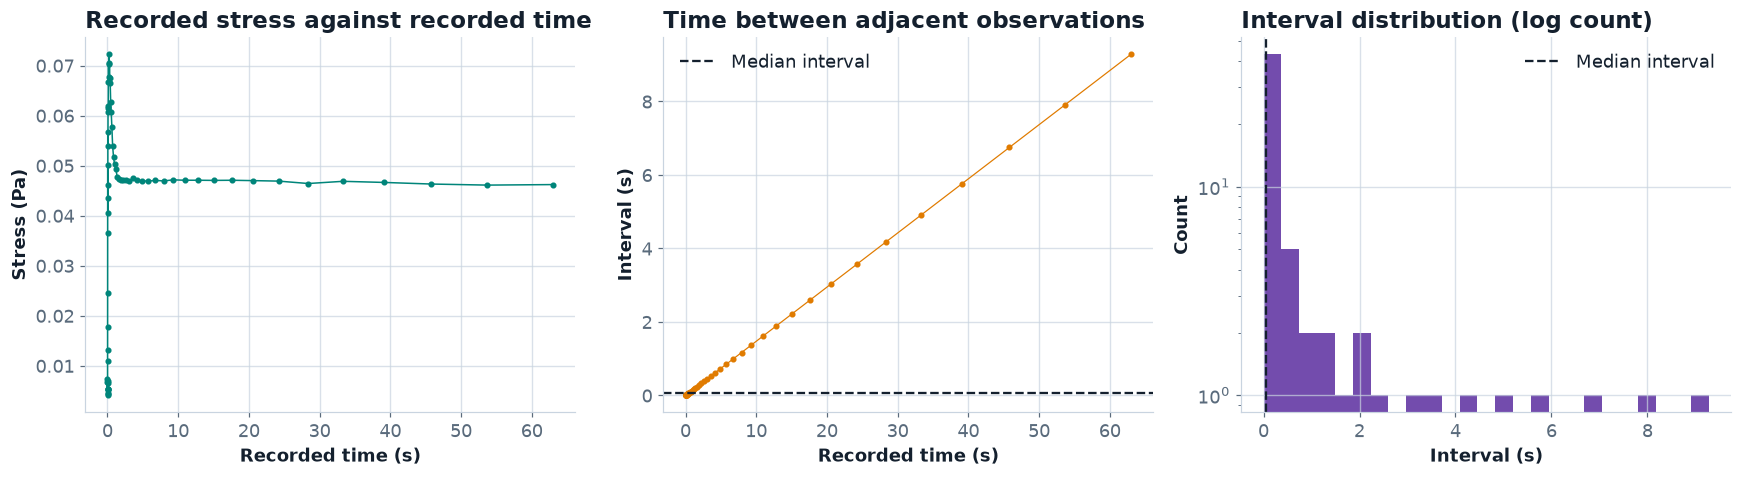

Interpretation rule: a short median interval does not repair long unsampled gaps.
All later transform eligibility decisions use the full interval distribution.


In [16]:
figure, sampling_axes = plt.subplots(1, 3, figsize=(16, 4.5))
sampling_intervals = np.diff(primary_raw_time)
sampling_axes[0].plot(primary_raw_time, primary_raw_stress, color=COLOUR_WINNER, marker="o",
                      markersize=3, linewidth=1)
sampling_axes[0].set_title("Recorded stress against recorded time", loc="left")
sampling_axes[0].set_xlabel("Recorded time (s)")

sampling_axes[0].set_ylabel("Stress (Pa)")

sampling_axes[1].plot(primary_raw_time[1:], sampling_intervals, color=COLOUR_ACCENT, marker=".",
                      linewidth=0.8)
sampling_axes[1].axhline(primary_sampling_diagnostics["median_interval_s"], color=COLOUR_TEXT,
                        linestyle="--", label="Median interval")
sampling_axes[1].set_title("Time between adjacent observations", loc="left")
sampling_axes[1].set_xlabel("Recorded time (s)")
sampling_axes[1].set_ylabel("Interval (s)")
sampling_axes[1].legend()

sampling_axes[2].hist(sampling_intervals, bins=25, color=COLOUR_RUNNERUP, alpha=0.85)
sampling_axes[2].axvline(primary_sampling_diagnostics["median_interval_s"], color=COLOUR_TEXT,
                          linestyle="--", label="Median interval")
sampling_axes[2].set_yscale("log")
sampling_axes[2].set_title("Interval distribution (log count)", loc="left")
sampling_axes[2].set_xlabel("Interval (s)")
sampling_axes[2].set_ylabel("Count")
sampling_axes[2].legend()

plt.tight_layout()
plt.show()

print("Interpretation rule: a short median interval does not repair long unsampled gaps.")
print("All later transform eligibility decisions use the full interval distribution.")


## 3. Conservative preprocessing and support rules

Using a trial-specific uniform grid only when a transform requires one. Interpolating is restricted to short gaps, and no values are extrapolated beyond the first or last observation. Linear detrending is not applied by default because it can remove the stress relaxation being studied.

In [17]:
def regularize_only_supported_gaps(time_values, signal_values, sampling_frequency_hz,
                                   maximum_gap_multiple=5.0):
    """Interpolating nearby observations while preserving long-gap exclusions."""
    observed_time = np.asarray(time_values, dtype=float)
    observed_signal = np.asarray(signal_values, dtype=float)
    finite_mask = np.isfinite(observed_time) & np.isfinite(observed_signal)
    observed_time = observed_time[finite_mask]
    observed_signal = observed_signal[finite_mask]
    sort_order = np.argsort(observed_time)
    observed_time = observed_time[sort_order]
    observed_signal = observed_signal[sort_order]
    observed_time, unique_indices = np.unique(observed_time, return_index=True)
    observed_signal = observed_signal[unique_indices]
    diagnostics = calculate_sampling_diagnostics(observed_time)
    if len(observed_time) < 8 or not np.isfinite(diagnostics["median_interval_s"]):
        return {"supported": False, "reason": "too few usable observations", "diagnostics": diagnostics}
    interval_limit = maximum_gap_multiple * diagnostics["median_interval_s"]
    if diagnostics["maximum_interval_s"] > interval_limit:
        return {"supported": False, "reason": "gap exceeds declared support limit", "diagnostics": diagnostics}
    grid_interval = 1.0 / float(sampling_frequency_hz)
    output_count = int(np.floor((observed_time[-1] - observed_time[0]) / grid_interval)) + 1
    uniform_time = observed_time[0] + np.arange(output_count) * grid_interval
    uniform_time = uniform_time[uniform_time <= observed_time[-1]]
    uniform_signal = np.interp(uniform_time, observed_time, observed_signal)
    nearest_right = np.clip(np.searchsorted(observed_time, uniform_time), 0, len(observed_time) - 1)
    nearest_left = np.maximum(nearest_right - 1, 0)
    near_observation = np.minimum(np.abs(uniform_time - observed_time[nearest_right]),
                                  np.abs(uniform_time - observed_time[nearest_left])) < grid_interval * 1e-6
    return {"supported": True, "reason": "supported short-gap interpolation",
            "time": uniform_time, "signal": uniform_signal,
            "support_mask": np.ones(output_count, dtype=bool)[:len(uniform_time)],
            "sampling_frequency_hz": float(sampling_frequency_hz), "diagnostics": diagnostics,
            "interpolated_fraction": float(1.0 - near_observation.mean())}


print("Preprocessing policy: retain raw observations; use trial-specific rate; interpolate short gaps only;")
print("reject unsupported windows; preserve the stress level and transient shape by default.")


Preprocessing policy: retain raw observations; use trial-specific rate; interpolate short gaps only;
reject unsupported windows; preserve the stress level and transient shape by default.


## 4. Auditing the five-workbook real-data scope

Repeating the source notebook’s five-workbook step-up scan and recording sampling support. These measurements have no independent physical onset labels, so this table is a data-quality audit rather than a method leaderboard.

In [18]:
def parse_step_condition(condition_label):
    """Reading an initial and final shear rate from a workbook condition label."""
    cleaned_label = str(condition_label).replace("(1/s)", "").replace(" ", "")
    if "-->" not in cleaned_label:
        return np.nan, np.nan, None
    label_parts = cleaned_label.split("-->")
    if len(label_parts) != 2:
        return np.nan, np.nan, None
    try:
        initial_rate = float(label_parts[0])
        final_rate = float(label_parts[1])
    except ValueError:
        return np.nan, np.nan, None
    return initial_rate, final_rate, final_rate > initial_rate


def find_step_sheet_names(workbook_handle):
    """Finding workbook sheets with step-test records, independent of exact naming."""
    return [sheet_name for sheet_name in workbook_handle.sheet_names
            if "step" in sheet_name.lower()]

ARMSTRONG_STEP_UP_WORKBOOKS = ["data8.xlsx", "data5.xlsx", "data9.xlsx", "data7.xlsx", "data1.xlsx"]
real_step_audit_rows = []


#### Continuing the calculation


In [19]:
for workbook_name in ARMSTRONG_STEP_UP_WORKBOOKS:
    workbook_path = os.path.join(DATA_DIRECTORY, workbook_name)
    if not os.path.isfile(workbook_path):
        print("Skipping missing workbook:", workbook_name)
        continue

    workbook_handle = pd.ExcelFile(workbook_path)
    for sheet_name in find_step_sheet_names(workbook_handle):
        try:
            workbook_blocks = parse_multiblock_sheet(workbook_path, sheet_name)
        except Exception as workbook_read_error:
            print("Could not parse", workbook_name, sheet_name, "->", workbook_read_error)
            continue

        for block_index, block in enumerate(workbook_blocks):
            starting_shear_rate, ending_shear_rate, is_step_up = parse_step_condition(block["label"])
            if is_step_up is not True:
                continue
            extracted_values = extract_time_series(block)
            if extracted_values is None:
                continue

            block_time, block_stress = extracted_values
            block_diagnostics = calculate_sampling_diagnostics(block_time)
            real_step_audit_rows.append({
                "measurement_id": f"{workbook_name}:{sheet_name}:{block_index}:{block['label']}",
                "workbook": workbook_name,
                "condition": block["label"],
                "initial_shear_rate_per_s": starting_shear_rate,
                "final_shear_rate_per_s": ending_shear_rate,
                **block_diagnostics,
            })

real_step_audit_table = pd.DataFrame(real_step_audit_rows)
if len(real_step_audit_table) > 0:
    display(real_step_audit_table.round(4))
    print("Step-up measurements audited:", len(real_step_audit_table))
    print("These measurements do not have independently observed clot-time labels.")
else:
    print("No real step-up records could be parsed; check DATA_DIRECTORY and workbook layouts.")


,measurement_id,workbook,condition,initial_shear_rate_per_s,final_shear_rate_per_s,sample_count,duration_s,median_interval_s,equivalent_rate_hz,mean_interval_s,interval_cv,p90_interval_s,p99_interval_s,maximum_interval_s,p90_to_median_gap,maximum_to_median_gap
0,data8.xlsx:Step Up Step Down:5:.25-->.5(1/s),data8.xlsx,.25-->.5(1/s),0.25,0.50,65,62.9999,0.0613,16.3024,0.9844,2.0388,3.4093,8.4232,9.2854,55.5802,151.3747
1,data8.xlsx:Step Up Step Down:6:.25-->1(1/s),data8.xlsx,.25-->1(1/s),0.25,1.00,65,62.9999,0.0613,16.3024,0.9844,2.0388,3.4093,8.4232,9.2853,55.5802,151.3731
2,data8.xlsx:Step Up Step Down:7:.25-->2.5(1/s),data8.xlsx,.25-->2.5(1/s),0.25,2.50,65,62.9999,0.0613,16.3024,0.9844,2.0388,3.4093,8.4232,9.2853,55.5802,151.3731
3,data8.xlsx:Step Up Step Down:8:.25-->5(1/s),data8.xlsx,.25-->5(1/s),0.25,5.00,65,62.9999,0.0613,16.3026,0.9844,2.0388,3.4093,8.4231,9.2854,55.5796,151.3759
4,data8.xlsx:Step Up Step Down:9:.1-->.25(1/s),data8.xlsx,.1-->.25(1/s),0.10,0.25,65,63.0003,0.0613,16.3024,0.9844,2.0387,3.4093,8.4232,9.2852,55.5804,151.3714
5,data8.xlsx:Step Up Step Down:10:.1-->.5(1/s),data8.xlsx,.1-->.5(1/s),0.10,0.50,65,62.9997,0.0613,16.3024,0.9844,2.0388,3.4093,8.4231,9.2853,55.5793,151.3731
6,data8.xlsx:Step Up Step Down:11:.1-->1 (1/s),data8.xlsx,.1-->1 (1/s),0.10,1.00,65,62.9999,0.0613,16.3024,0.9844,2.0388,3.4093,8.4232,9.2854,55.5791,151.3747
7,data8.xlsx:Step Up Step Down:12:.1-->2.5 (1/s),data8.xlsx,.1-->2.5 (1/s),0.10,2.50,65,62.9999,0.0613,16.3024,0.9844,2.0388,3.4093,8.4232,9.2854,55.5798,151.3747
8,data8.xlsx:Step Up Step Down:13:.1-->5 (1/s),data8.xlsx,.1-->5 (1/s),0.10,5.00,65,62.9997,0.0614,16.2862,0.9844,2.0388,3.4093,8.4231,9.2854,55.5244,151.2243
9,data5.xlsx:STEP UP-DOWN:5:.25-->.5(1/s),data5.xlsx,.25-->.5(1/s),0.25,0.50,65,62.9998,0.0613,16.3024,0.9844,2.0388,3.4093,8.4231,9.2853,55.5802,151.3731


Step-up measurements audited: 53
These measurements do not have independently observed clot-time labels.


## 5. Carrying forward and scoping the paper model

Keeping the paper implementation from the first notebook as a model-based reference. The original solver is retained for continuity. A separate segmented solver below applies a known input step at a declared time, avoiding the original assumption that the step occurred at the first recorded sample.

In [20]:
from scipy.integrate import solve_ivp


def compute_steady_state_lambda(shear_rate, tr1, tr2):
    """
    Computing the structure level a material settles to if held at a
    constant shear rate forever.

    This is Equation 16 from the paper, the same expression we proved
    correct in Cell 3 by deriving it independently from Equation 13.
    Used here only to set a realistic starting point for the simulation,
    not as part of the time-stepping itself.
    """
    absolute_shear_rate = abs(float(shear_rate))
    numerator   = tr2 * np.sqrt(absolute_shear_rate) + 1.0
    denominator = tr1 * absolute_shear_rate + tr2 * np.sqrt(absolute_shear_rate) + 1.0
    return numerator / denominator


def get_paper_initial_state(model_parameters, initial_shear_rate, model_version=1):
    """Calculating the paper's steady state before applying a shear step."""
    initial_lambda = compute_steady_state_lambda(initial_shear_rate,
                                                model_parameters["tr1"], model_parameters["tr2"])
    viscosity = initial_lambda * model_parameters["eta_structural"]
    if model_version == 1:
        viscosity += model_parameters["eta_infinity"]
    initial_stress = initial_lambda * model_parameters["sigma_y0"] + viscosity * initial_shear_rate
    return [initial_stress, initial_lambda]


#### Make paper derivative


In [21]:
def make_paper_derivative(model_parameters, shear_rate_function, model_version=1):
    """Building the coupled derivatives from paper Equations 11 and 13."""
    elastic_modulus = model_parameters["G_elastic"] if model_version == 1 else model_parameters["G_rouleaux"]
    brownian_rate = model_parameters["k_lambda"] if model_version == 1 else model_parameters["k_lambda_v2"]
    def system_derivatives(current_time, state_vector):
        current_stress, current_lambda = state_vector
        bounded_lambda = float(np.clip(current_lambda, 1e-9, 1.0))
        viscosity = bounded_lambda * model_parameters["eta_structural"]
        if model_version == 1:
            viscosity += model_parameters["eta_infinity"]
        absolute_stress = abs(current_stress)
        denominator = viscosity * absolute_stress
        plastic_flow = 0.0
        if denominator > 1e-14:
            plastic_flow = max(0.0, (absolute_stress - bounded_lambda * model_parameters["sigma_y0"]) / denominator)
        stress_derivative = elastic_modulus * (shear_rate_function(current_time) - plastic_flow * current_stress)
        plastic_shear_rate = plastic_flow * absolute_stress
        structure_derivative = brownian_rate * (
            -model_parameters["tr1"] * plastic_shear_rate * bounded_lambda
            + model_parameters["tr2"] * np.sqrt(plastic_shear_rate) * (1.0 - bounded_lambda)
            + (1.0 - bounded_lambda)
        )
        return [stress_derivative, structure_derivative]
    return system_derivatives


def simulate_ethixo_evp(shear_rate_function, time_span, model_parameters,
                        initial_shear_rate, model_version=1, number_of_output_points=2000):
    """Retaining the paper solver interface and checking integration success."""
    output_time_grid = np.linspace(time_span[0], time_span[1], number_of_output_points)
    solution = solve_ivp(make_paper_derivative(model_parameters, shear_rate_function, model_version),
                         time_span, get_paper_initial_state(model_parameters, initial_shear_rate, model_version),
                         t_eval=output_time_grid, method="LSODA", rtol=1e-8, atol=1e-11)
    if not solution.success:
        raise RuntimeError(solution.message)
    simulated_stress = solution.y[0]
    if model_version == 2:
        applied_rates = np.array([shear_rate_function(moment) for moment in solution.t])
        simulated_stress = simulated_stress + model_parameters["eta_infinity"] * applied_rates
    return solution.t, simulated_stress, np.clip(solution.y[1], 0.0, 1.0)


#### Simulate evp only baseline


In [22]:
def simulate_evp_only_baseline(shear_rate_function, time_span, model_parameters,
                                initial_shear_rate, number_of_output_points=2000):
    """
    Solving the simpler EVP-only model, the version with no structure
    parameter at all. Included purely as a point of comparison, this is
    what you would predict if you ignored thixotropy entirely.
    """
    sigma_y0        = model_parameters["sigma_y0"]
    consistency_k   = model_parameters["consistency_k"]
    power_law_n     = model_parameters["power_law_n"]
    elastic_modulus = model_parameters["G_evp_only"]

    def system_derivative(current_time, state_vector):
        current_stress = state_vector[0]
        applied_shear_rate = shear_rate_function(current_time)
        absolute_stress = abs(current_stress)

        if absolute_stress > 1e-14:
            yield_numerator = absolute_stress - sigma_y0
            if yield_numerator > 0:
                plastic_flow_term = (yield_numerator / (consistency_k * absolute_stress ** power_law_n))
                plastic_flow_term = max(0.0, plastic_flow_term) ** (1.0 / power_law_n)
            else:
                plastic_flow_term = 0.0
        else:
            plastic_flow_term = 0.0

        stress_derivative = elastic_modulus * (applied_shear_rate - plastic_flow_term * current_stress)
        return [stress_derivative]

    initial_stress = sigma_y0 + consistency_k * (abs(initial_shear_rate) ** power_law_n)
    output_time_grid = np.linspace(time_span[0], time_span[1], number_of_output_points)

    solution = solve_ivp(
        system_derivative,
        time_span,
        [initial_stress],
        t_eval=output_time_grid,
        method="LSODA",
        rtol=1e-8,
        atol=1e-11,
    )

    return solution.t, solution.y[0]


#### Model interpretation and provenance

- Equation 13 evolves the internal structure variable $\lambda$. Equation 11 evolves stress; Equation 16 gives the steady-state structure used to initialise the simulation.
- The carried-forward parameter values are fixed example values from the original notebook’s transcription of the paper. They are not fitted to each Armstrong experiment.
- $\lambda(t)$ is a latent state in the constitutive model. It cannot be observed directly in the raw workbooks and is not a clot-time label.
- The synthetic validation below uses the equations to create controlled stress responses with known input-step times, then adds declared instrument-like distortions. Performance claims remain limited to those simulated conditions.

## 6. Generating model-based synthetic trials with known event times

Creating 20 distinct scenarios with five repeat trials each. The exact commanded shear-rate step is the primary known timestamp. The stress response follows the paper’s coupled equations, and the synthetic layer adds noise, drift, ringing, harmonic contamination, irregular timestamps, missing samples, or clipping as declared. These experiments test transient timing; they do not simulate a clinical clot endpoint.

Event times are randomized independently of method settings, avoiding alignment of every known step with PELT’s candidate grid or STFT’s frame clock. The seed fixes this randomization for reproducibility.

In [23]:
from scipy.integrate import solve_ivp
from scipy import signal as scipy_signal
from scipy.ndimage import gaussian_filter1d


def solve_paper_model_around_known_step(time_values, event_time_s, initial_shear_rate,
                                        final_shear_rate, model_parameters):
    """Solving the post-step interval from an exactly declared initial state."""
    output_time = np.asarray(time_values, dtype=float)
    initial_state = get_paper_initial_state(model_parameters, initial_shear_rate)
    model_stress = np.full(len(output_time), initial_state[0], dtype=float)
    model_lambda = np.full(len(output_time), initial_state[1], dtype=float)
    post_step_mask = output_time >= event_time_s
    requested_post_time = output_time[post_step_mask]
    if len(requested_post_time) == 0:
        return model_stress, model_lambda
    post_step_time = np.unique(np.concatenate(([event_time_s], requested_post_time)))
    derivative_function = make_paper_derivative(model_parameters, lambda current_time: final_shear_rate)
    solution = solve_ivp(derivative_function, (event_time_s, float(output_time[-1])), initial_state,
                         t_eval=post_step_time, method="LSODA", rtol=1e-8, atol=1e-11,
                         max_step=max(float(np.median(np.diff(output_time))) / 4.0, 1e-4))
    if not solution.success:
        raise RuntimeError(solution.message)
    model_stress[post_step_mask] = np.interp(requested_post_time, solution.t, solution.y[0])
    model_lambda[post_step_mask] = np.clip(np.interp(requested_post_time, solution.t, solution.y[1]), 0.0, 1.0)
    return model_stress, model_lambda



scenario_specs = []


#### Continuing the calculation


In [24]:
base_scenario_specs = [
    ("rate_10_hz", 10.0, 0.1, 5.0, 38.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("rate_25_hz", 25.0, 0.1, 5.0, 38.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("rate_50_hz", 50.0, 0.1, 5.0, 38.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("rate_100_hz", 100.0, 0.1, 5.0, 38.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("snr_40_db", 50.0, 0.1, 5.0, 40.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("snr_25_db", 50.0, 0.1, 5.0, 25.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("snr_15_db", 50.0, 0.1, 5.0, 15.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("snr_10_db", 50.0, 0.1, 5.0, 10.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("small_step", 50.0, 0.1, 1.0, 30.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("medium_step", 50.0, 0.1, 5.0, 30.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("large_step", 50.0, 0.1, 15.0, 30.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("reverse_direction", 50.0, 5.0, 0.1, 30.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("weaker_breakdown", 50.0, 0.1, 5.0, 30.0, 0.45, 0.20, 0.00, 0.00, 0.00, 0.00, False),
    ("stronger_breakdown", 50.0, 0.1, 5.0, 30.0, 1.30, 0.55, 0.00, 0.00, 0.00, 0.00, False),
    ("baseline_drift", 50.0, 0.1, 5.0, 25.0, 0.77, 0.34, 0.20, 0.00, 0.00, 0.00, False),
    ("ringing", 50.0, 0.1, 5.0, 25.0, 0.77, 0.34, 0.00, 0.12, 0.00, 0.00, False),
    ("harmonic_contamination", 50.0, 0.1, 5.0, 25.0, 0.77, 0.34, 0.00, 0.00, 0.08, 0.00, False),
    ("jittered_clock", 50.0, 0.1, 5.0, 25.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.20, False),
    ("missing_samples", 50.0, 0.1, 5.0, 25.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, False),
    ("clipped_and_dropout", 50.0, 0.1, 5.0, 25.0, 0.77, 0.34, 0.00, 0.00, 0.00, 0.00, True),
]

for scenario_tuple in base_scenario_specs:
    scenario_specs.append({
        "scenario_id": scenario_tuple[0],
        "sampling_frequency_hz": scenario_tuple[1],
        "initial_shear_rate": scenario_tuple[2],
        "final_shear_rate": scenario_tuple[3],
        "snr_db": scenario_tuple[4],
        "tr1": scenario_tuple[5],
        "tr2": scenario_tuple[6],
        "baseline_drift_fraction": scenario_tuple[7],
        "ringing_fraction": scenario_tuple[8],
        "harmonic_fraction": scenario_tuple[9],
        "clock_jitter_fraction": scenario_tuple[10],
        "clipping": scenario_tuple[11],
    })

# Assigning additional sampling/dropout controls explicitly, keeping scenario definitions auditable.
for scenario_specification in scenario_specs:
    scenario_specification["random_dropout_fraction"] = 0.0
    scenario_specification["dropout_across_event"] = False
scenario_specs[17]["random_dropout_fraction"] = 0.0
scenario_specs[18]["random_dropout_fraction"] = 0.03
scenario_specs[19]["random_dropout_fraction"] = 0.01
scenario_specs[19]["dropout_across_event"] = True
scenario_specs[19]["clipping"] = True


#### Continuing the calculation


In [25]:
SYNTHETIC_EVENT_CENTRE_S = 60.0
SYNTHETIC_EVENT_JITTER_S = 3.0
SYNTHETIC_DURATION_S = 120.0
SYNTHETIC_REPLICATE_COUNT = 5
SYNTHETIC_RANDOM_SEED = 90106


def add_declared_instrument_effects(clean_stress, uniform_time, scenario_specification, random_generator, event_time_s):
    """Adding declared noise and distortions to the clean model stress."""
    post_event_mask = uniform_time >= event_time_s
    stress_scale = max(float(np.std(clean_stress[post_event_mask])), 1e-8)
    time_since_step = np.maximum(uniform_time - event_time_s, 0.0)
    measured_stress = clean_stress.copy()
    measured_stress += scenario_specification["baseline_drift_fraction"] * stress_scale * uniform_time / SYNTHETIC_DURATION_S
    measured_stress += scenario_specification["ringing_fraction"] * stress_scale * (
        np.exp(-time_since_step / 2.5) * np.sin(2.0 * np.pi * 1.5 * time_since_step) * post_event_mask)
    harmonic_component = scenario_specification["harmonic_fraction"] * stress_scale * np.sin(2.0 * np.pi * 2.0 * uniform_time)
    measured_stress += harmonic_component
    noise_standard_deviation = stress_scale / (10.0 ** (scenario_specification["snr_db"] / 20.0))
    coloured_noise = scipy_signal.lfilter([1.0], [1.0, -0.65], random_generator.normal(0.0, 1.0, len(uniform_time)))
    coloured_noise /= max(float(np.std(coloured_noise)), 1e-12)
    measured_stress += noise_standard_deviation * coloured_noise
    spike_count = int(round(len(uniform_time) * 0.001))
    if spike_count > 0:
        spike_indices = random_generator.choice(len(uniform_time), size=spike_count, replace=False)
        measured_stress[spike_indices] += random_generator.choice([-1.0, 1.0], size=spike_count) * 4.0 * noise_standard_deviation
    if scenario_specification["clipping"]:
        clipping_limit = float(np.quantile(np.abs(measured_stress), 0.98))
        measured_stress = np.clip(measured_stress, -clipping_limit, clipping_limit)
    total_distortion = measured_stress - clean_stress
    measured_snr = 20.0 * np.log10(stress_scale / max(float(np.std(total_distortion[post_event_mask])), 1e-12))
    harmonic_rms_ratio = float(np.std(harmonic_component) / stress_scale)
    return measured_stress, measured_snr, harmonic_rms_ratio


#### Sample with clock and dropouts


In [26]:
def sample_with_clock_and_dropouts(uniform_time, measured_stress, scenario_specification, random_generator, event_time_s):
    """Applying timestamp jitter and missing observations without shifting truth."""
    observed_time = uniform_time.copy()
    sampling_frequency = scenario_specification["sampling_frequency_hz"]
    jitter_fraction = scenario_specification["clock_jitter_fraction"]
    if jitter_fraction > 0:
        time_jitter = random_generator.uniform(-jitter_fraction / sampling_frequency,
                                               jitter_fraction / sampling_frequency, len(observed_time))
        time_jitter[0] = 0.0
        time_jitter[-1] = 0.0
        observed_time += time_jitter
    observed_stress = np.interp(observed_time, uniform_time, measured_stress)
    keep_mask = np.ones(len(observed_time), dtype=bool)
    dropout_fraction = scenario_specification["random_dropout_fraction"]
    if dropout_fraction > 0:
        dropout_count = max(1, int(round(len(observed_time) * dropout_fraction)))
        dropout_indices = random_generator.choice(np.arange(1, len(observed_time) - 1),
                                                   size=dropout_count, replace=False)
        keep_mask[dropout_indices] = False
    if scenario_specification["dropout_across_event"]:
        keep_mask[(observed_time > event_time_s - 0.7)
                  & (observed_time < event_time_s + 0.7)] = False
    return observed_time[keep_mask], observed_stress[keep_mask]


def generate_controlled_synthetic_trial(scenario_specification, replicate_number,
                                        model_parameters, random_generator):
    """Generating one recorded synthetic trial and its separate truth arrays."""
    sampling_frequency = float(scenario_specification["sampling_frequency_hz"])
    event_time = SYNTHETIC_EVENT_CENTRE_S + random_generator.uniform(-SYNTHETIC_EVENT_JITTER_S, SYNTHETIC_EVENT_JITTER_S)
    uniform_time = np.arange(0.0, SYNTHETIC_DURATION_S, 1.0 / sampling_frequency)
    trial_parameters = dict(model_parameters)
    trial_parameters["tr1"] = scenario_specification["tr1"]
    trial_parameters["tr2"] = scenario_specification["tr2"]
    clean_stress, structure_trace = solve_paper_model_around_known_step(
        uniform_time, event_time, scenario_specification["initial_shear_rate"],
        scenario_specification["final_shear_rate"], trial_parameters)
    measured_stress, measured_snr, harmonic_rms_ratio = add_declared_instrument_effects(
        clean_stress, uniform_time, scenario_specification, random_generator, event_time)
    observed_time, observed_stress = sample_with_clock_and_dropouts(
        uniform_time, measured_stress, scenario_specification, random_generator, event_time)
    return {"scenario_id": scenario_specification["scenario_id"], "replicate": replicate_number,
            "time": observed_time, "stress": observed_stress, "clean_time": uniform_time,
            "clean_stress": clean_stress, "structure_lambda": structure_trace,
            "event_time_s": event_time, "sampling_frequency_hz": sampling_frequency,
            "target_snr_db": scenario_specification["snr_db"], "measured_snr_db": measured_snr,
            "injected_harmonic_rms_ratio": harmonic_rms_ratio, "scenario": scenario_specification}


#### Continuing the calculation


In [27]:
synthetic_random_generator = np.random.default_rng(SYNTHETIC_RANDOM_SEED)
synthetic_trials = []

for scenario_specification in scenario_specs:
    for replicate_number in range(1, SYNTHETIC_REPLICATE_COUNT + 1):
        synthetic_trial = generate_controlled_synthetic_trial(
            scenario_specification,
            replicate_number,
            PAPER_PARAMETERS_DONOR3,
            synthetic_random_generator,
        )
        synthetic_trials.append(synthetic_trial)

scenario_description_rows = []
for scenario_specification in scenario_specs:
    scenario_description_rows.append({
        "scenario_id": scenario_specification["scenario_id"],
        "sampling_rate_hz": scenario_specification["sampling_frequency_hz"],
        "shear_step_per_s": str(scenario_specification["initial_shear_rate"])
            + " to " + str(scenario_specification["final_shear_rate"]),
        "target_snr_db": scenario_specification["snr_db"],
        "tr1_s": scenario_specification["tr1"],
        "tr2_sqrt_s": scenario_specification["tr2"],
        "baseline_drift": scenario_specification["baseline_drift_fraction"],
        "ringing": scenario_specification["ringing_fraction"],
        "harmonic": scenario_specification["harmonic_fraction"],
        "clock_jitter_fraction": scenario_specification["clock_jitter_fraction"],
        "random_dropout_fraction": scenario_specification["random_dropout_fraction"],
        "gap_across_event": scenario_specification["dropout_across_event"],
        "clipping": scenario_specification["clipping"],
        "replicates": SYNTHETIC_REPLICATE_COUNT,
    })

synthetic_scenario_table = pd.DataFrame(scenario_description_rows)
display(synthetic_scenario_table)
print("Synthetic scenarios:", len(scenario_specs))
print("Synthetic trials:", len(synthetic_trials))
print("Known event definition: the commanded shear-rate step, randomized between",
      SYNTHETIC_EVENT_CENTRE_S - SYNTHETIC_EVENT_JITTER_S, "and",
      SYNTHETIC_EVENT_CENTRE_S + SYNTHETIC_EVENT_JITTER_S, "seconds")


,scenario_id,sampling_rate_hz,shear_step_per_s,target_snr_db,tr1_s,tr2_sqrt_s,baseline_drift,ringing,harmonic,clock_jitter_fraction,random_dropout_fraction,gap_across_event,clipping,replicates
0,rate_10_hz,10.0,0.1 to 5.0,38.0,0.77,0.34,0.0,0.00,0.00,0.0,0.00,False,False,5
1,rate_25_hz,25.0,0.1 to 5.0,38.0,0.77,0.34,0.0,0.00,0.00,0.0,0.00,False,False,5
2,rate_50_hz,50.0,0.1 to 5.0,38.0,0.77,0.34,0.0,0.00,0.00,0.0,0.00,False,False,5
3,rate_100_hz,100.0,0.1 to 5.0,38.0,0.77,0.34,0.0,0.00,0.00,0.0,0.00,False,False,5
4,snr_40_db,50.0,0.1 to 5.0,40.0,0.77,0.34,0.0,0.00,0.00,0.0,0.00,False,False,5
5,snr_25_db,50.0,0.1 to 5.0,25.0,0.77,0.34,0.0,0.00,0.00,0.0,0.00,False,False,5
6,snr_15_db,50.0,0.1 to 5.0,15.0,0.77,0.34,0.0,0.00,0.00,0.0,0.00,False,False,5
7,snr_10_db,50.0,0.1 to 5.0,10.0,0.77,0.34,0.0,0.00,0.00,0.0,0.00,False,False,5
8,small_step,50.0,0.1 to 1.0,30.0,0.77,0.34,0.0,0.00,0.00,0.0,0.00,False,False,5
9,medium_step,50.0,0.1 to 5.0,30.0,0.77,0.34,0.0,0.00,0.00,0.0,0.00,False,False,5


Synthetic scenarios: 20
Synthetic trials: 100
Known event definition: the commanded shear-rate step, randomized between 57.0 and 63.0 seconds


## 7. Checking the controlled signal and its timing truth

Showing one representative signal with the known command step, the model-predicted stress response, and the latent structure variable. The vertical line marks the known input event; the stress and structure curves are generated responses, not measured clot times.

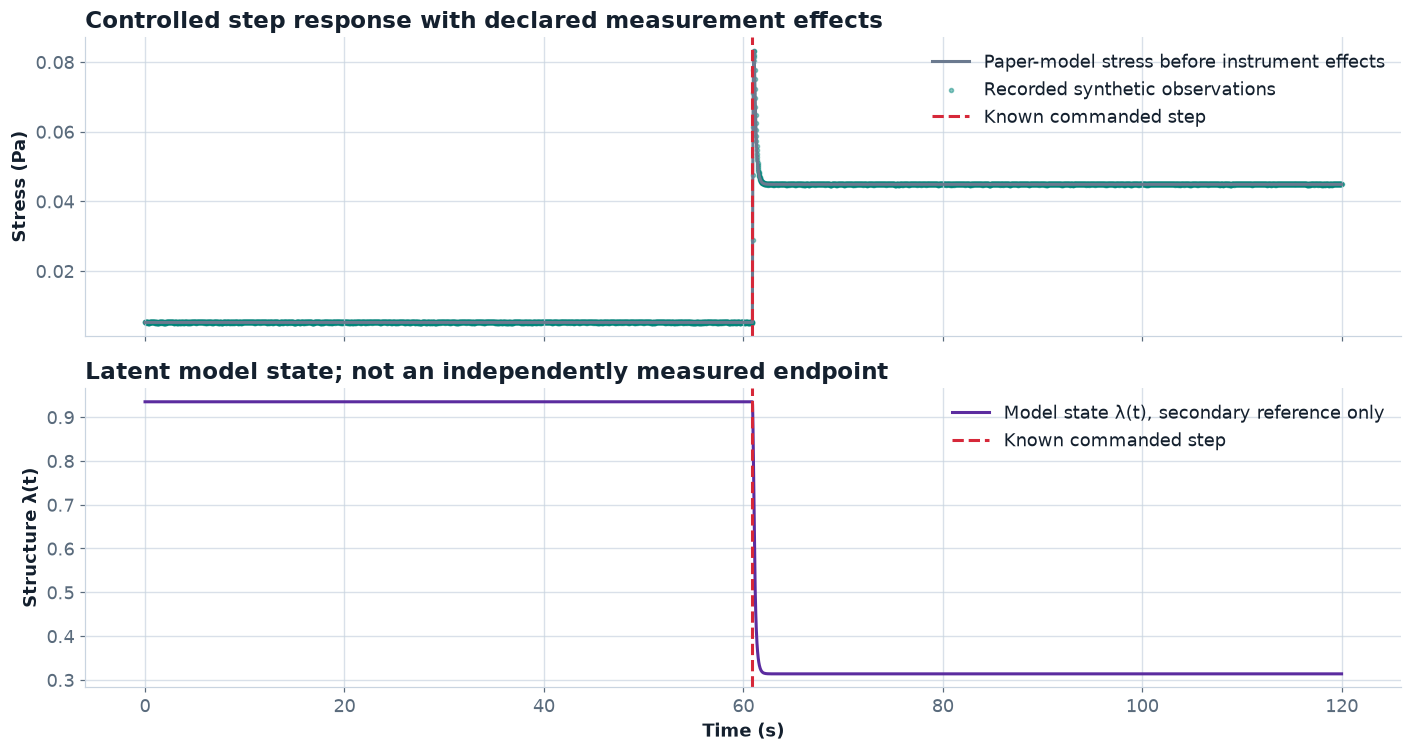

Representative measured SNR: 37.79 dB
Known event time: 60.900998886804665 s


In [28]:
representative_trial = next(
    trial for trial in synthetic_trials if trial["scenario_id"] == "rate_50_hz" and trial["replicate"] == 1
)

figure, synthetic_axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
synthetic_axes[0].plot(representative_trial["clean_time"], representative_trial["clean_stress"],
                       color=COLOUR_NEUTRAL, linewidth=2, label="Paper-model stress before instrument effects")
synthetic_axes[0].scatter(representative_trial["time"], representative_trial["stress"],
                          color=COLOUR_WINNER, s=7, alpha=0.45, label="Recorded synthetic observations")
synthetic_axes[0].axvline(representative_trial["event_time_s"], color=COLOUR_BASELINE,
                         linewidth=2, linestyle="--", label="Known commanded step")
synthetic_axes[0].set_ylabel("Stress (Pa)")
synthetic_axes[0].set_title("Controlled step response with declared measurement effects", loc="left")
synthetic_axes[0].legend()

synthetic_axes[1].plot(representative_trial["clean_time"], representative_trial["structure_lambda"],
                       color=COLOUR_RUNNERUP, linewidth=2, label="Model state λ(t), secondary reference only")
synthetic_axes[1].axvline(representative_trial["event_time_s"], color=COLOUR_BASELINE,
                         linewidth=2, linestyle="--", label="Known commanded step")
synthetic_axes[1].set_xlabel("Time (s)")
synthetic_axes[1].set_ylabel("Structure λ(t)")
synthetic_axes[1].set_title("Latent model state; not an independently measured endpoint", loc="left")
synthetic_axes[1].legend()

plt.tight_layout()
plt.show()

print("Representative measured SNR:", round(representative_trial["measured_snr_db"], 2), "dB")
print("Known event time:", representative_trial["event_time_s"], "s")


## 8. Shared transform settings and detector definitions

Applying all time-local methods to the same short-gap-regularized samples. The physical analysis band is fixed at 0.5–4 Hz where the sampling rate supports it; each result records the actual upper limit. STFT uses the same 4-second window duration and 75% overlap. DWT levels are selected from their approximate octave bands and reported as coarser time support.

The 120-second synthetic records place the known input step at a separately randomized time between 57 and 63 seconds in each trial. A fixed 25–35 second baseline precedes the event and lies inside every retained kernel’s valid support. Each detector receives signal values and fixed settings; known event times are accessed only after detection for scoring. PyWavelets guards use conservative full kernel bounds; Morse and fCWT guards use a centered impulse radius containing 99.5% of coefficient energy. Paul uses a conservative five-scale guard. DWT reports the actual approximate octave union and its analysis-plus-reconstruction filter support; its passband is coarser than the continuous methods. Morse scales use the generalized Morse wavelet’s continuous peak frequency; the finite FFT-bin conversion is also checked by the library. SSQ uses its returned frequency labels with the library’s default row orientation. No support guard is capped to force a method into the comparison.

PELT considers a breakpoint every 0.2 seconds at every sampling rate; this explicit grid bounds computational cost and is recorded with the results. Its timestamp resolution is therefore coarser than the sample clock.

In [29]:
COMMON_MINIMUM_FREQUENCY_HZ = 0.5
COMMON_MAXIMUM_FREQUENCY_HZ = 4.0
CWT_FREQUENCY_COUNT = 48
STFT_WINDOW_SECONDS = 4.0
STFT_OVERLAP_FRACTION = 0.75
TIMING_SMOOTHING_SECONDS = 0.15
BASELINE_START_S = 25.0
BASELINE_END_S = 35.0
TRANSFORM_SUPPORT_CACHE = {}
TIMING_TOLERANCE_SECONDS = [0.25, 0.5, 1.0]
PELT_JUMP_SECONDS = 0.2


def feature_to_event_time(feature_time, feature_values, baseline_start_time,
                          baseline_end_time, edge_guard_seconds=0.0):
    """Selecting an event from the feature without receiving the known answer."""
    feature_time = np.asarray(feature_time, dtype=float)
    feature_values = np.asarray(feature_values, dtype=float)
    finite_mask = np.isfinite(feature_time) & np.isfinite(feature_values)
    feature_time = feature_time[finite_mask]
    feature_values = feature_values[finite_mask]
    interior_start = feature_time[0] + edge_guard_seconds
    interior_end = feature_time[-1] - edge_guard_seconds
    if baseline_start_time < interior_start or baseline_end_time > interior_end:
        return {"detected_time_s": np.nan, "status": "unsupported baseline"}
    baseline_mask = (feature_time >= baseline_start_time) & (feature_time < baseline_end_time)
    if baseline_mask.sum() < 5 or len(feature_values) < 8:
        return {"detected_time_s": np.nan, "status": "insufficient baseline"}
    baseline_median = float(np.median(feature_values[baseline_mask]))
    baseline_mad = float(np.median(np.abs(feature_values[baseline_mask] - baseline_median)))
    robust_scale = max(1.4826 * baseline_mad, float(np.std(feature_values[baseline_mask]) * 0.1), 1e-12)
    scaled_feature = (feature_values - baseline_median) / robust_scale
    feature_interval = float(np.median(np.diff(feature_time)))
    smoothing_sigma = TIMING_SMOOTHING_SECONDS / feature_interval / 2.355
    if smoothing_sigma >= 0.5:
        smoothed_feature = gaussian_filter1d(scaled_feature, sigma=smoothing_sigma, mode="nearest")
    else:
        smoothed_feature = scaled_feature.copy()
    feature_gradient = np.gradient(smoothed_feature, feature_time)
    searchable_mask = (feature_time >= interior_start) & (feature_time <= interior_end)
    if not np.any(searchable_mask):
        return {"detected_time_s": np.nan, "status": "no interior support"}
    candidate_indices = np.flatnonzero(searchable_mask)
    detected_index = candidate_indices[np.argmax(np.abs(feature_gradient[searchable_mask]))]
    return {"detected_time_s": float(feature_time[detected_index]), "status": "detected",
            "baseline_scale": robust_scale}


#### Calculate shared log band rms


In [30]:
def calculate_shared_log_band_rms(frequency_values, power_values, maximum_supported_frequency_hz):
    """Mapping spectral power onto one shared logarithmic frequency grid."""
    frequency_values = np.asarray(frequency_values, dtype=float).ravel()
    power_values = np.asarray(power_values, dtype=float)
    if power_values.ndim == 1:
        power_values = power_values[:, np.newaxis]

    valid_frequency_mask = np.isfinite(frequency_values) & (frequency_values > 0)
    frequency_values = frequency_values[valid_frequency_mask]
    power_values = power_values[valid_frequency_mask, :]
    sorted_positions = np.argsort(frequency_values)
    frequency_values = frequency_values[sorted_positions]
    power_values = power_values[sorted_positions, :]

    if frequency_values[0] > COMMON_MINIMUM_FREQUENCY_HZ * (1.0 + 1e-5):
        raise ValueError("This method does not resolve the lower edge of the common frequency band.")
    if frequency_values[-1] < maximum_supported_frequency_hz * (1.0 - 1e-5):
        raise ValueError("This method does not resolve the upper edge of the common frequency band.")

    shared_frequency_grid = np.geomspace(
        COMMON_MINIMUM_FREQUENCY_HZ,
        maximum_supported_frequency_hz,
        CWT_FREQUENCY_COUNT,
    )
    log_frequency_values = np.log(frequency_values)
    log_shared_frequency_grid = np.log(shared_frequency_grid)
    shared_power_values = np.empty((len(shared_frequency_grid), power_values.shape[1]), dtype=float)

    for time_position in range(power_values.shape[1]):
        shared_power_values[:, time_position] = np.interp(
            log_shared_frequency_grid,
            log_frequency_values,
            power_values[:, time_position],
        )

    rms_feature_values = np.sqrt(np.mean(np.maximum(shared_power_values, 0.0), axis=0))
    return rms_feature_values, shared_frequency_grid


import pywt


#### Compute paul wavelet cwt


In [31]:
def compute_paul_wavelet_cwt(signal_values, scales, sampling_period, paul_order=4):
    """Computing the Paul wavelet with scales and angular frequency in sample units."""
    import math
    signal_length = len(signal_values)
    signal_spectrum = np.fft.fft(signal_values - np.mean(signal_values))
    angular_frequencies = 2.0 * np.pi * np.fft.fftfreq(signal_length)
    normalization = (2.0 ** paul_order) / np.sqrt(paul_order * math.factorial(2 * paul_order - 1))
    coefficients = np.zeros((len(scales), signal_length), dtype=complex)
    for scale_index, scale_value in enumerate(scales):
        scaled_frequencies = scale_value * angular_frequencies
        positive_mask = scaled_frequencies > 0
        wavelet_spectrum = np.zeros(signal_length, dtype=float)
        wavelet_spectrum[positive_mask] = (normalization * scaled_frequencies[positive_mask] ** paul_order
                                           * np.exp(-scaled_frequencies[positive_mask]))
        wavelet_spectrum *= np.sqrt(2.0 * np.pi * scale_value)
        coefficients[scale_index] = np.fft.ifft(signal_spectrum * wavelet_spectrum)
    conversion_factor = 4.0 * np.pi / (2.0 * paul_order + 1.0)
    frequencies = 1.0 / (conversion_factor * np.asarray(scales) * sampling_period)
    return coefficients, frequencies



def get_common_frequency_grid(sampling_frequency_hz):
    """Declaring one physical band and logarithmic grid for the spectral methods."""
    maximum_frequency = min(COMMON_MAXIMUM_FREQUENCY_HZ, 0.45 * sampling_frequency_hz)
    return np.geomspace(COMMON_MINIMUM_FREQUENCY_HZ, maximum_frequency, CWT_FREQUENCY_COUNT)


def get_morse_energy_guard(signal_length, sampling_frequency, scales):
    """Caching a Morse impulse-response guard for each clock and record length."""
    from ssqueezepy import cwt
    cache_key = ("Morse", signal_length, sampling_frequency)
    if cache_key not in TRANSFORM_SUPPORT_CACHE:
        impulse_signal = np.zeros(signal_length)
        impulse_signal[signal_length // 2] = 1.0
        impulse_coefficients, actual_scales = cwt(impulse_signal, wavelet="gmw", scales=scales,
                                                  fs=sampling_frequency, padtype="reflect")
        TRANSFORM_SUPPORT_CACHE[cache_key] = calculate_kernel_energy_guard(impulse_coefficients, sampling_frequency)
    return TRANSFORM_SUPPORT_CACHE[cache_key]


#### Calculate kernel energy guard


In [32]:
def calculate_kernel_energy_guard(coefficient_matrix, sampling_frequency_hz, energy_fraction=0.995):
    """Estimating impulse-response support containing 99.5% of each row's energy."""
    coefficient_power = np.abs(coefficient_matrix) ** 2
    sample_count = coefficient_power.shape[1]
    distance_samples = np.abs(np.arange(sample_count) - sample_count // 2)
    distance_order = np.argsort(distance_samples)
    maximum_radius = 0
    for row_power in coefficient_power:
        cumulative_power = np.cumsum(row_power[distance_order])
        if cumulative_power[-1] <= 0:
            continue
        threshold_position = np.searchsorted(cumulative_power, energy_fraction * cumulative_power[-1])
        maximum_radius = max(maximum_radius, int(distance_samples[distance_order[threshold_position]]))
    return maximum_radius / sampling_frequency_hz


def run_continuous_wavelet_transform(signal_values, sampling_frequency, wavelet_name, number_of_scales=48):
    """Converting each original CWT family's scales to the common physical band."""
    frequency_grid = get_common_frequency_grid(sampling_frequency)
    sampling_period = 1.0 / sampling_frequency
    if wavelet_name == "Paul":
        scales = (9.0 / (4.0 * np.pi)) / (frequency_grid * sampling_period)
        coefficients, frequencies = compute_paul_wavelet_cwt(signal_values, scales, sampling_period)
        edge_guard = 5.0 * float(np.max(scales)) * sampling_period
    elif wavelet_name == "Morse":
        from ssqueezepy import Wavelet, cwt
        from ssqueezepy.experimental import scale_to_freq
        wavelet_object = Wavelet("gmw")
        scales = wavelet_object.wc_ct / (2.0 * np.pi * frequency_grid[::-1] * sampling_period)
        coefficients, actual_scales = cwt(np.asarray(signal_values, dtype=float), wavelet=wavelet_object,
                                          scales=scales, fs=sampling_frequency, padtype="reflect")
        discrete_peak_frequencies = scale_to_freq(actual_scales, wavelet_object, len(signal_values), fs=sampling_frequency)
        frequencies = wavelet_object.wc_ct * sampling_frequency / (2.0 * np.pi * actual_scales)
        edge_guard = get_morse_energy_guard(len(signal_values), sampling_frequency, scales)
    else:
        wavelet_names = {"Morlet": "morl", "DOG": "gaus4", "Shannon": "shan1.0-1.0"}
        wavelet_object = pywt.ContinuousWavelet(wavelet_names[wavelet_name])
        scales = pywt.central_frequency(wavelet_object) / (frequency_grid * sampling_period)
        coefficients, frequencies = pywt.cwt(signal_values, scales, wavelet_object,
                                              sampling_period=sampling_period, method="fft")
        bound = max(abs(wavelet_object.lower_bound), abs(wavelet_object.upper_bound))
        edge_guard = bound * float(np.max(scales)) * sampling_period
    return {"success": True, "coefficients": np.asarray(coefficients), "magnitude": np.abs(coefficients),
            "frequencies": np.asarray(frequencies).ravel(), "edge_guard_s": edge_guard,
            "message": "computed on common physical band"}


#### Calculate cwt energy feature


In [33]:
def calculate_cwt_energy_feature(signal_values, sampling_frequency_hz, wavelet_name):
    """Reducing each original CWT family's common-band power to an energy trace."""
    result = run_continuous_wavelet_transform(signal_values, sampling_frequency_hz, wavelet_name)
    maximum_frequency = get_common_frequency_grid(sampling_frequency_hz)[-1]
    feature, common_grid = calculate_shared_log_band_rms(result["frequencies"], result["magnitude"] ** 2,
                                                        maximum_frequency)
    return {"time": np.arange(len(signal_values)) / sampling_frequency_hz, "feature": feature,
            "frequency_min_hz": common_grid[0], "frequency_max_hz": common_grid[-1],
            "frequency_count": len(common_grid), "nominal_time_support_s": result["edge_guard_s"]}



def calculate_fcwt_energy_feature(signal_values, sampling_frequency_hz):
    """Computing fCWT on the shared band and recording its impulse support."""
    fcwt = load_fcwt_module()
    frequency_grid = get_common_frequency_grid(sampling_frequency_hz)
    frequencies, coefficients = fcwt.cwt(np.asarray(signal_values, dtype=np.float32), int(sampling_frequency_hz),
                                        float(frequency_grid[0]), float(frequency_grid[-1]), len(frequency_grid),
                                        nthreads=1, scaling="log")
    feature, common_grid = calculate_shared_log_band_rms(frequencies, np.abs(coefficients) ** 2, frequency_grid[-1])
    cache_key = ("fCWT", len(signal_values), sampling_frequency_hz)
    if cache_key not in TRANSFORM_SUPPORT_CACHE:
        impulse_signal = np.zeros(len(signal_values), dtype=np.float32)
        impulse_signal[len(signal_values) // 2] = 1.0
        impulse_frequencies, impulse_coefficients = fcwt.cwt(impulse_signal, int(sampling_frequency_hz),
                                                            float(frequency_grid[0]), float(frequency_grid[-1]),
                                                            len(frequency_grid), nthreads=1, scaling="log")
        TRANSFORM_SUPPORT_CACHE[cache_key] = calculate_kernel_energy_guard(impulse_coefficients, sampling_frequency_hz)
    return {"time": np.arange(len(signal_values)) / sampling_frequency_hz, "feature": feature,
            "frequency_min_hz": common_grid[0], "frequency_max_hz": common_grid[-1],
            "frequency_count": len(common_grid), "nominal_time_support_s": TRANSFORM_SUPPORT_CACHE[cache_key]}



def run_synchrosqueezed_cwt(signal_values, sampling_frequency):
    """Returning SSQ-CWT coefficients without executing a demonstration signal."""
    from ssqueezepy import Wavelet, ssq_cwt
    frequency_grid = get_common_frequency_grid(sampling_frequency)
    wavelet_object = Wavelet("gmw")
    scales = wavelet_object.wc_ct * sampling_frequency / (2.0 * np.pi * frequency_grid[::-1])
    squeezed_coefficients, regular_coefficients, squeezed_frequencies, returned_scales = ssq_cwt(
        np.asarray(signal_values, dtype=float), wavelet=wavelet_object, scales=scales,
        ssq_freqs=frequency_grid, fs=sampling_frequency, flipud=True, padtype="reflect")
    edge_guard = get_morse_energy_guard(len(signal_values), sampling_frequency, scales)
    return {"success": True, "magnitude": np.abs(squeezed_coefficients),
            "frequencies": np.asarray(squeezed_frequencies).ravel(), "edge_guard_s": edge_guard}


#### Calculate ssq energy feature


In [34]:
def calculate_ssq_energy_feature(signal_values, sampling_frequency_hz):
    """Reducing SSQ-CWT common-band power while preserving frequency row alignment."""
    result = run_synchrosqueezed_cwt(signal_values, sampling_frequency_hz)
    maximum_frequency = get_common_frequency_grid(sampling_frequency_hz)[-1]
    feature, common_grid = calculate_shared_log_band_rms(result["frequencies"], result["magnitude"] ** 2,
                                                        maximum_frequency)
    return {"time": np.arange(len(signal_values)) / sampling_frequency_hz, "feature": feature,
            "frequency_min_hz": common_grid[0], "frequency_max_hz": common_grid[-1],
            "frequency_count": len(common_grid), "nominal_time_support_s": result["edge_guard_s"]}


#### Calculate stft energy feature


In [35]:
def calculate_stft_energy_feature(signal_values, sampling_frequency_hz, window_name):
    """Calculating STFT band energy with a duration-matched analysis window."""
    signal_values = np.asarray(signal_values, dtype=float)
    window_length = min(len(signal_values), max(8, int(round(STFT_WINDOW_SECONDS * sampling_frequency_hz))))
    overlap_length = min(window_length - 1, int(round(STFT_OVERLAP_FRACTION * window_length)))
    if window_name == "hann":
        window_values = scipy_signal.get_window("hann", window_length)
    else:
        window_values = scipy_signal.windows.gaussian(window_length, std=window_length / 7.0)

    frequency_values, local_time, complex_spectrogram = scipy_signal.stft(
        signal_values,
        fs=sampling_frequency_hz,
        window=window_values,
        nperseg=window_length,
        noverlap=overlap_length,
        boundary=None,
        padded=False,
    )
    maximum_supported_frequency = min(COMMON_MAXIMUM_FREQUENCY_HZ, 0.45 * sampling_frequency_hz)
    feature_values, shared_frequency_grid = calculate_shared_log_band_rms(
        frequency_values, np.abs(complex_spectrogram) ** 2, maximum_supported_frequency
    )
    return {
        "time": local_time,
        "feature": feature_values,
        "frequency_min_hz": COMMON_MINIMUM_FREQUENCY_HZ,
        "frequency_max_hz": maximum_supported_frequency,
        "frequency_count": int(len(shared_frequency_grid)),
        "nominal_time_support_s": window_length / (2.0 * sampling_frequency_hz),
        "window_length_samples": window_length,
        "window_duration_s": window_length / sampling_frequency_hz,
        "overlap_fraction": overlap_length / window_length,
    }


#### Calculate dwt energy feature


In [36]:
def calculate_dwt_energy_feature(signal_values, sampling_frequency_hz, wavelet_name):
    """Reconstructing overlapping DWT octaves and reporting their actual union."""
    wavelet_object = pywt.Wavelet(wavelet_name)
    maximum_level = pywt.dwt_max_level(len(signal_values), wavelet_object.dec_len)
    decomposition_level = min(7, maximum_level)
    if decomposition_level < 1:
        raise ValueError("Signal too short for DWT.")
    coefficients = pywt.wavedec(signal_values, wavelet_object, level=decomposition_level, mode="symmetric")
    band_power = np.zeros(len(signal_values))
    selected_levels = []
    for detail_level in range(1, decomposition_level + 1):
        lower_frequency = sampling_frequency_hz / (2.0 ** (detail_level + 1))
        upper_frequency = sampling_frequency_hz / (2.0 ** detail_level)
        if upper_frequency <= COMMON_MINIMUM_FREQUENCY_HZ or lower_frequency >= COMMON_MAXIMUM_FREQUENCY_HZ:
            continue
        isolated_coefficients = [np.zeros_like(coefficient) for coefficient in coefficients]
        position = decomposition_level - detail_level + 1
        isolated_coefficients[position] = coefficients[position]
        reconstructed_detail = pywt.waverec(isolated_coefficients, wavelet_object, mode="symmetric")[:len(signal_values)]
        band_power += reconstructed_detail ** 2
        selected_levels.append(detail_level)
    if len(selected_levels) == 0:
        raise ValueError("No DWT octave overlaps the requested band.")
    edge_guard = ((wavelet_object.dec_len + wavelet_object.rec_len - 2)
                  * (2 ** max(selected_levels) - 1) / (2.0 * sampling_frequency_hz))
    return {"time": np.arange(len(signal_values)) / sampling_frequency_hz,
            "feature": np.sqrt(band_power / len(selected_levels)),
            "frequency_min_hz": COMMON_MINIMUM_FREQUENCY_HZ, "frequency_max_hz": COMMON_MAXIMUM_FREQUENCY_HZ,
            "approximate_band_min_hz": sampling_frequency_hz / (2.0 ** (max(selected_levels) + 1)),
            "approximate_band_max_hz": sampling_frequency_hz / (2.0 ** min(selected_levels)),
            "frequency_count": len(selected_levels), "selected_levels": selected_levels,
            "nominal_time_support_s": edge_guard}


#### Calculate global fft summary


#### Caching PELT’s unchanged segment-loss calculation

Cumulative sums preserve the library’s L2 cost while avoiding repeated scans of each candidate segment. The candidate time grid remains an explicit 0.2 seconds.


In [37]:
from ruptures.base import BaseCost
from ruptures.exceptions import NotEnoughPoints

class PrefixSumL2Cost(BaseCost):
    """Computing the same L2 segment loss with cached cumulative sums."""
    model = "l2"
    def __init__(self):
        self.signal = None
        self.min_size = 1
    def fit(self, signal_values):
        signal_values = np.asarray(signal_values, dtype=float)
        if signal_values.ndim != 1:
            raise ValueError("This cost expects one stress column.")
        self.signal = signal_values.reshape(-1, 1)
        self.cumulative_values = np.concatenate(([0.0], np.cumsum(signal_values)))
        self.cumulative_squares = np.concatenate(([0.0], np.cumsum(signal_values ** 2)))
        return self
    def error(self, start, end):
        sample_count = end - start
        if sample_count < self.min_size:
            raise NotEnoughPoints
        segment_sum = self.cumulative_values[end] - self.cumulative_values[start]
        segment_square_sum = self.cumulative_squares[end] - self.cumulative_squares[start]
        return max(0.0, float(segment_square_sum - segment_sum ** 2 / sample_count))


In [38]:
from ruptures.costs import CostL2
cost_check_signal = np.random.default_rng(90106).normal(size=2000)
reference_segment_cost = CostL2().fit(cost_check_signal)
optimized_segment_cost = PrefixSumL2Cost().fit(cost_check_signal)
for segment_start, segment_end in [(0, 20), (100, 650), (900, 1850), (0, 2000)]:
    assert np.isclose(reference_segment_cost.error(segment_start, segment_end),
                       optimized_segment_cost.error(segment_start, segment_end), rtol=1e-10, atol=1e-9)
print("Cached PELT segment loss matches the library's original L2 criterion.")


Cached PELT segment loss matches the library's original L2 criterion.


In [39]:
def calculate_global_fft_summary(signal_values, sampling_frequency_hz):
    """Summarizing the whole-record FFT; it has no time-local event estimate."""
    centered_signal = np.asarray(signal_values, dtype=float) - np.mean(signal_values)
    window_values = scipy_signal.windows.hann(len(centered_signal), sym=False)
    spectrum_values = np.fft.rfft(centered_signal * window_values)
    frequency_values = np.fft.rfftfreq(len(centered_signal), d=1.0 / sampling_frequency_hz)
    power_values = np.abs(spectrum_values) ** 2
    maximum_supported_frequency = min(COMMON_MAXIMUM_FREQUENCY_HZ, 0.45 * sampling_frequency_hz)
    band_mask = (frequency_values >= COMMON_MINIMUM_FREQUENCY_HZ) & (
        frequency_values <= maximum_supported_frequency
    )
    return {
        "frequency_hz": frequency_values,
        "power": power_values,
        "band_energy": float(np.sum(power_values[band_mask])),
        "frequency_resolution_hz": sampling_frequency_hz / len(centered_signal),
        "timing_capable": False,
    }


def calculate_pelt_event_time(signal_values, sampling_frequency_hz):
    """Selecting PELT's strongest measured mean shift without accessing truth."""
    import ruptures
    normalized_signal = (np.asarray(signal_values) - np.mean(signal_values)) / max(float(np.std(signal_values)), 1e-12)
    minimum_size = max(5, int(sampling_frequency_hz * 0.2))
    algorithm = ruptures.Pelt(custom_cost=PrefixSumL2Cost(), min_size=minimum_size,
                              jump=max(1, int(round(sampling_frequency_hz * PELT_JUMP_SECONDS)))).fit(normalized_signal)
    breakpoint_indices = algorithm.predict(pen=3.0 * np.log(len(normalized_signal)))
    comparison_samples = max(3, int(sampling_frequency_hz))
    candidates = []
    for breakpoint_index in breakpoint_indices:
        if breakpoint_index < comparison_samples or breakpoint_index >= len(normalized_signal) - comparison_samples:
            continue
        before_mean = float(np.mean(normalized_signal[breakpoint_index - comparison_samples:breakpoint_index]))
        after_mean = float(np.mean(normalized_signal[breakpoint_index:breakpoint_index + comparison_samples]))
        candidates.append((abs(after_mean - before_mean), breakpoint_index))
    if len(candidates) == 0:
        return {"detected_time_s": np.nan, "status": "no breakpoint", "candidate_count": 0}
    selected_strength, selected_index = max(candidates, key=lambda candidate: candidate[0])
    return {"detected_time_s": selected_index / sampling_frequency_hz,
            "status": "detected", "candidate_count": len(candidates), "pelt_candidate_grid_s": PELT_JUMP_SECONDS}


#### Get transform method specifications


In [40]:
def get_transform_method_specifications():
    """Listing the original fifteen methods once for paired evaluation."""
    specifications = []
    for wavelet_name in ["Morlet", "Paul", "DOG", "Shannon", "Morse"]:
        specifications.append(("CWT-" + wavelet_name, "CWT", calculate_cwt_energy_feature, wavelet_name))
    specifications.append(("fCWT", "fast CWT", calculate_fcwt_energy_feature, None))
    specifications.append(("SSQ-CWT", "synchrosqueezed CWT", calculate_ssq_energy_feature, None))
    for window_label, window_name in [("Hann", "hann"), ("Gaussian", "gaussian")]:
        specifications.append(("STFT-" + window_label, "STFT", calculate_stft_energy_feature, window_name))
    for wavelet_name in ["db4", "sym4", "coif1", "bior2.2", "rbio2.2"]:
        specifications.append(("DWT-" + wavelet_name, "DWT", calculate_dwt_energy_feature, wavelet_name))
    return specifications


def make_trial_metadata(trial, regularized_result):
    """Keeping run identities, noise levels, and sampling decisions in every row."""
    return {"scenario_id": trial["scenario_id"], "replicate": trial["replicate"],
            "event_time_s": trial["event_time_s"], "sampling_frequency_hz": trial["sampling_frequency_hz"],
            "target_snr_db": trial["target_snr_db"], "measured_snr_db": trial["measured_snr_db"],
            "sampling_supported": regularized_result.get("supported", False),
            "support_reason": regularized_result.get("reason", "unknown")}


def score_detected_timestamp(detection_result, known_event_time):
    """Comparing the selected timestamp with truth only after detection has finished."""
    detected_time = detection_result.get("detected_time_s", np.nan)
    signed_offset = detected_time - known_event_time if np.isfinite(detected_time) else np.nan
    return {**detection_result, "signed_offset_s": signed_offset,
            "absolute_offset_s": abs(signed_offset) if np.isfinite(signed_offset) else np.nan}


#### Evaluate one transform


In [41]:
def evaluate_one_transform(trial, uniform_signal, metadata, specification):
    """Applying one transformation and scoring its independently chosen event."""
    method_name, family_name, transform_function, transform_argument = specification
    started_at = time.perf_counter()
    try:
        if transform_argument is None:
            feature_result = transform_function(uniform_signal, trial["sampling_frequency_hz"])
        else:
            feature_result = transform_function(uniform_signal, trial["sampling_frequency_hz"], transform_argument)
        detection = feature_to_event_time(feature_result["time"], feature_result["feature"],
                                          BASELINE_START_S, BASELINE_END_S,
                                          edge_guard_seconds=feature_result["nominal_time_support_s"])
        outcome = score_detected_timestamp(detection, trial["event_time_s"])
        aligned_lambda = np.interp(feature_result["time"], trial["clean_time"], trial["structure_lambda"])
        secondary_correlation = float(scipy_stats.spearmanr(feature_result["feature"], aligned_lambda).statistic)
        return {**metadata, "method": method_name, "family": family_name, **outcome,
                "spearman_lambda_secondary": secondary_correlation,
                "runtime_ms": 1000.0 * (time.perf_counter() - started_at),
                "frequency_min_hz": feature_result["frequency_min_hz"],
                "frequency_max_hz": feature_result["frequency_max_hz"],
                "approximate_band_min_hz": feature_result.get("approximate_band_min_hz", np.nan),
                "approximate_band_max_hz": feature_result.get("approximate_band_max_hz", np.nan),
                "frequency_or_level_count": feature_result["frequency_count"],
                "nominal_time_support_s": feature_result["nominal_time_support_s"]}
    except Exception as transform_error:
        return {**metadata, "method": method_name, "family": family_name,
                "detected_time_s": np.nan, "signed_offset_s": np.nan, "absolute_offset_s": np.nan,
                "spearman_lambda_secondary": np.nan, "runtime_ms": 1000.0 * (time.perf_counter() - started_at),
                "status": "failed: " + str(transform_error)}


#### Evaluate trial methods


In [42]:
def evaluate_trial_methods(trial):
    """Evaluating the same supported observations with every original method."""
    regularized_result = regularize_only_supported_gaps(trial["time"], trial["stress"],
                                                       trial["sampling_frequency_hz"], maximum_gap_multiple=5.0)
    metadata = make_trial_metadata(trial, regularized_result)
    specifications = get_transform_method_specifications()
    if not regularized_result["supported"]:
        rejected_rows = []
        for method_name, family_name, transform_function, transform_argument in specifications + [("PELT", "changepoint", None, None)]:
            rejected_rows.append({**metadata, "method": method_name, "family": family_name,
                                  "detected_time_s": np.nan, "signed_offset_s": np.nan,
                                  "absolute_offset_s": np.nan, "spearman_lambda_secondary": np.nan,
                                  "runtime_ms": np.nan, "status": "unsupported sampling"})
        return rejected_rows
    uniform_signal = regularized_result["signal"]
    output_rows = []
    for specification in specifications:
        output_rows.append(evaluate_one_transform(trial, uniform_signal, metadata, specification))
    started_at = time.perf_counter()
    try:
        pelt_outcome = score_detected_timestamp(calculate_pelt_event_time(uniform_signal, trial["sampling_frequency_hz"]),
                                                trial["event_time_s"])
    except Exception as detection_error:
        pelt_outcome = {"detected_time_s": np.nan, "signed_offset_s": np.nan, "absolute_offset_s": np.nan,
                        "status": "failed: " + str(detection_error)}
    output_rows.append({**metadata, "method": "PELT", "family": "changepoint", **pelt_outcome,
                        "spearman_lambda_secondary": np.nan,
                        "runtime_ms": 1000.0 * (time.perf_counter() - started_at)})
    return output_rows


print("Shared physical band:", COMMON_MINIMUM_FREQUENCY_HZ, "to",
      COMMON_MAXIMUM_FREQUENCY_HZ, "Hz, subject to Nyquist support")
print("Shared STFT window duration:", STFT_WINDOW_SECONDS, "s; overlap:", STFT_OVERLAP_FRACTION)
print("Transform features are mapped to a shared log-frequency grid before band averaging.")
print("Global FFT is reported as a frequency summary only; it cannot localize a transient in time.")


Shared physical band: 0.5 to 4.0 Hz, subject to Nyquist support
Shared STFT window duration: 4.0 s; overlap: 0.75
Transform features are mapped to a shared log-frequency grid before band averaging.
Global FFT is reported as a frequency summary only; it cannot localize a transient in time.


#### Checking physical frequency labels

A known 2 Hz tone checks the corrected Paul and Morse scale conversion and SSQ coefficient row alignment. This check validates implementation units; it does not tune event-detection settings.


In [43]:
tone_sampling_frequency_hz = 50.0
tone_time = np.arange(0.0, 120.0, 1.0 / tone_sampling_frequency_hz)
known_tone_frequency_hz = 2.0
tone_signal = np.sin(2.0 * np.pi * known_tone_frequency_hz * tone_time)
frequency_validation_rows = []
for wavelet_name in ["Paul", "Morse"]:
    transform_result = run_continuous_wavelet_transform(tone_signal, tone_sampling_frequency_hz, wavelet_name)
    tone_interior = (tone_time >= 25.0) & (tone_time <= 95.0)
    average_power = np.mean(transform_result["magnitude"][:, tone_interior] ** 2, axis=1)
    measured_peak = float(transform_result["frequencies"][np.argmax(average_power)])
    frequency_validation_rows.append({"method": "CWT-" + wavelet_name,
                                      "known_frequency_hz": known_tone_frequency_hz,
                                      "peak_frequency_hz": measured_peak})
ssq_tone_result = run_synchrosqueezed_cwt(tone_signal, tone_sampling_frequency_hz)
ssq_average_power = np.mean(ssq_tone_result["magnitude"][:, tone_interior] ** 2, axis=1)
frequency_validation_rows.append({"method": "SSQ-CWT", "known_frequency_hz": known_tone_frequency_hz,
                                  "peak_frequency_hz": float(ssq_tone_result["frequencies"][np.argmax(ssq_average_power)])})
frequency_validation_table = pd.DataFrame(frequency_validation_rows)
frequency_validation_table["absolute_frequency_error_hz"] = (
    frequency_validation_table["peak_frequency_hz"] - known_tone_frequency_hz).abs()
assert frequency_validation_table["absolute_frequency_error_hz"].max() < 0.25
frequency_validation_table.to_csv(RESULTS_DIRECTORY / "physical_frequency_validation.csv", index=False)
display(frequency_validation_table.round(4))
print("Physical frequency labels passed the predeclared 0.25 Hz validation tolerance.")


,method,known_frequency_hz,peak_frequency_hz,absolute_frequency_error_hz
0,CWT-Paul,2.0,1.9707,0.0293
1,CWT-Morse,2.0,1.9707,0.0293
2,SSQ-CWT,2.0,1.9707,0.0293


Physical frequency labels passed the predeclared 0.25 Hz validation tolerance.


## 9. Running paired synthetic comparisons

Each method receives the same supported trial and the same frequency band. Recording each transform’s timing offset, support, runtime, and secondary λ(t) rank correlation. An unsupported missing-event window is reported, not repaired.

In [44]:
import time
from scipy import stats as scipy_stats

synthetic_method_rows = []
for trial_number, trial in enumerate(synthetic_trials, start=1):
    trial_method_rows = evaluate_trial_methods(trial)
    synthetic_method_rows.extend(trial_method_rows)
    if trial_number % 10 == 0:
        print("Completed", trial_number, "of", len(synthetic_trials), "synthetic trials", flush=True)
        pd.DataFrame(synthetic_method_rows).to_csv(RESULTS_DIRECTORY / "benchmark_progress.csv", index=False)

synthetic_method_results = pd.DataFrame(synthetic_method_rows)
synthetic_supported_results = synthetic_method_results[
    synthetic_method_results["sampling_supported"]
    & synthetic_method_results["absolute_offset_s"].notna()
].copy()

if len(synthetic_method_results) > 0:
    distinct_trial_support = synthetic_method_results.drop_duplicates(["scenario_id", "replicate"])
    synthetic_support_summary = distinct_trial_support.groupby("scenario_id").agg(
        trial_count=("replicate", "count"),
        supported_trials=("sampling_supported", "sum"),
    ).reset_index()
    display(synthetic_support_summary)

print("Method-trial rows:", len(synthetic_method_results))
print("Supported method-trial rows with timing estimates:", len(synthetic_supported_results))
print("Unsupported trials are retained in the results table with an explicit reason.")


Completed 10 of 100 synthetic trials


Completed 20 of 100 synthetic trials


Completed 30 of 100 synthetic trials


Completed 40 of 100 synthetic trials


Completed 50 of 100 synthetic trials


...

Completed 80 of 100 synthetic trials


Completed 90 of 100 synthetic trials


Completed 100 of 100 synthetic trials


,scenario_id,trial_count,supported_trials
0,baseline_drift,5,5
1,clipped_and_dropout,5,0
2,harmonic_contamination,5,5
3,jittered_clock,5,5
4,large_step,5,5
5,medium_step,5,5
6,missing_samples,5,5
7,rate_100_hz,5,5
8,rate_10_hz,5,5
9,rate_25_hz,5,5


Method-trial rows: 1500
Supported method-trial rows with timing estimates: 1425
Unsupported trials are retained in the results table with an explicit reason.


#### Recording transform support and parameters


In [45]:
transform_parameter_table = synthetic_method_results[synthetic_method_results["sampling_supported"]].groupby(
    ["method", "sampling_frequency_hz"]
).agg(
    requested_low_hz=("frequency_min_hz", "median"),
    requested_high_hz=("frequency_max_hz", "median"),
    approximate_dwt_low_hz=("approximate_band_min_hz", "median"),
    approximate_dwt_high_hz=("approximate_band_max_hz", "median"),
    frequency_or_level_count=("frequency_or_level_count", "median"),
    boundary_guard_s=("nominal_time_support_s", "median"),
).reset_index()
transform_parameter_table.to_csv(RESULTS_DIRECTORY / "transform_parameter_table.csv", index=False)
display(transform_parameter_table.round(4))
print("DWT octave bounds are approximate; their actual union is reported separately from the requested band.")


,method,sampling_frequency_hz,requested_low_hz,requested_high_hz,approximate_dwt_low_hz,approximate_dwt_high_hz,frequency_or_level_count,boundary_guard_s
0,CWT-DOG,10.0,0.5,4.0,NaN,NaN,48.0,5.000
1,CWT-DOG,25.0,0.5,4.0,NaN,NaN,48.0,5.000
2,CWT-DOG,50.0,0.5,4.0,NaN,NaN,48.0,5.000
3,CWT-DOG,100.0,0.5,4.0,NaN,NaN,48.0,5.000
4,CWT-Morlet,10.0,0.5,4.0,NaN,NaN,48.0,13.000
5,CWT-Morlet,25.0,0.5,4.0,NaN,NaN,48.0,13.000
6,CWT-Morlet,50.0,0.5,4.0,NaN,NaN,48.0,13.000
7,CWT-Morlet,100.0,0.5,4.0,NaN,NaN,48.0,13.000
8,CWT-Morse,10.0,0.5,4.0,NaN,NaN,48.0,8.500
9,CWT-Morse,25.0,0.5,4.0,NaN,NaN,48.0,8.480


DWT octave bounds are approximate; their actual union is reported separately from the requested band.


## 10. Event-timing metrics and interpretable plots

Reporting absolute timing error, signed bias, event hit rate within declared tolerances, misses, and computational time. These are timing metrics against the known synthetic input step. Correlation with model λ(t) remains a secondary diagnostic and is not used to choose the timing winner.

#### Global FFT: useful spectral summary, not an onset detector

The global FFT uses the whole record at once. It can summarize frequency content and resolution, but it discards when each component occurred. It is therefore reported alongside the time-local methods, not entered into the event-timing leaderboard.

,median_frequency_resolution_hz,median_shared_band_energy,timing_capable
scenario_id,,,
baseline_drift,0.0083,83.8681,False
harmonic_contamination,0.0083,83.8455,False
jittered_clock,0.0083,82.8711,False
large_step,0.0083,402.5499,False
medium_step,0.0083,83.9323,False
missing_samples,0.0083,83.8231,False
rate_100_hz,0.0083,335.0422,False
rate_10_hz,0.0083,3.4028,False
rate_25_hz,0.0083,20.9306,False


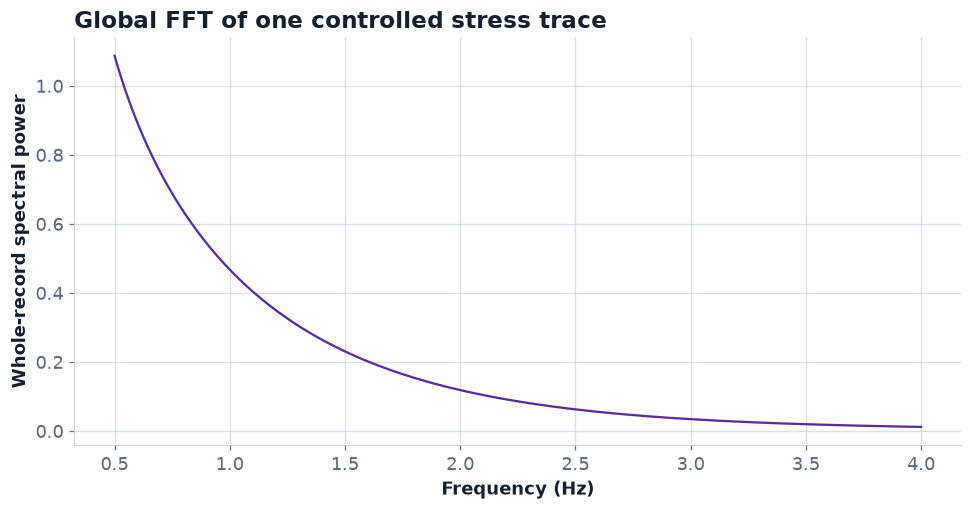

Global FFT timing_capable: False
Frequency resolution: 0.0083 Hz


In [46]:
fft_summary_rows = []
for trial in synthetic_trials:
    regularized_result = regularize_only_supported_gaps(
        trial["time"], trial["stress"], trial["sampling_frequency_hz"], maximum_gap_multiple=5.0
    )
    if not regularized_result.get("supported", False):
        continue
    fft_summary = calculate_global_fft_summary(
        regularized_result["signal"], trial["sampling_frequency_hz"]
    )
    fft_summary_rows.append({
        "scenario_id": trial["scenario_id"],
        "replicate": trial["replicate"],
        "frequency_resolution_hz": fft_summary["frequency_resolution_hz"],
        "shared_band_energy": fft_summary["band_energy"],
        "timing_capable": fft_summary["timing_capable"],
    })

synthetic_global_fft_summary = pd.DataFrame(fft_summary_rows)
display(synthetic_global_fft_summary.groupby("scenario_id").agg(
    median_frequency_resolution_hz=("frequency_resolution_hz", "median"),
    median_shared_band_energy=("shared_band_energy", "median"),
    timing_capable=("timing_capable", "first"),
).round(4))

fft_example = calculate_global_fft_summary(
    representative_trial["clean_stress"], representative_trial["sampling_frequency_hz"]
)
fft_frequency_mask = (
    (fft_example["frequency_hz"] >= COMMON_MINIMUM_FREQUENCY_HZ)
    & (fft_example["frequency_hz"] <= min(
        COMMON_MAXIMUM_FREQUENCY_HZ,
        0.45 * representative_trial["sampling_frequency_hz"],
    ))
)
figure, fft_axis = plt.subplots(figsize=(9, 4.8))
fft_axis.plot(fft_example["frequency_hz"][fft_frequency_mask],
              fft_example["power"][fft_frequency_mask], color=COLOUR_RUNNERUP)
fft_axis.set_xlabel("Frequency (Hz)")
fft_axis.set_ylabel("Whole-record spectral power")
fft_axis.set_title("Global FFT of one controlled stress trace", loc="left")
plt.tight_layout()
plt.show()

print("Global FFT timing_capable:", fft_example["timing_capable"])
print("Frequency resolution:", round(fft_example["frequency_resolution_hz"], 4), "Hz")


In [47]:
operational_results = synthetic_method_results[synthetic_method_results["sampling_supported"]].copy()
operational_results["detected"] = operational_results["detected_time_s"].notna()
operational_results["failed"] = operational_results["status"].str.startswith("failed")
operational_results["rank_error_s"] = operational_results["absolute_offset_s"].fillna(SYNTHETIC_DURATION_S)
for tolerance_seconds, column_name in [(0.25, "within_0_25_s"), (0.5, "within_0_5_s"), (1.0, "within_1_0_s")]:
    operational_results[column_name] = operational_results["absolute_offset_s"].le(tolerance_seconds).fillna(False)

method_performance_summary = operational_results.groupby(["method", "family"]).agg(
    trial_count=("detected", "size"), detected_trials=("detected", "sum"),
    detection_coverage=("detected", "mean"), failed_trials=("failed", "sum"),
    median_absolute_error_s=("absolute_offset_s", "median"),
    mean_absolute_error_s=("absolute_offset_s", "mean"),
    median_signed_bias_s=("signed_offset_s", "median"),
    hit_rate_0_25_s=("within_0_25_s", "mean"), hit_rate_0_5_s=("within_0_5_s", "mean"),
    hit_rate_1_0_s=("within_1_0_s", "mean"), median_runtime_ms=("runtime_ms", "median"),
    median_lambda_spearman_secondary=("spearman_lambda_secondary", "median"),
).reset_index().sort_values("median_absolute_error_s")
display(method_performance_summary.round(4))
print("Hit-rate denominators include every sampling-supported trial, including misses and failures.")
print("Conditional timing-error summaries describe detected events; ranking scores penalize missing detections.")


,method,family,trial_count,detected_trials,detection_coverage,failed_trials,median_absolute_error_s,mean_absolute_error_s,median_signed_bias_s,hit_rate_0_25_s,hit_rate_0_5_s,hit_rate_1_0_s,median_runtime_ms,median_lambda_spearman_secondary
10,PELT,changepoint,95,95,1.0,0,0.0518,0.0526,0.0173,1.0000,1.0000,1.0000,102.6191,NaN
0,CWT-DOG,CWT,95,95,1.0,0,0.0973,0.0972,0.0973,1.0000,1.0000,1.0000,13.0335,0.0335
1,CWT-Morlet,CWT,95,95,1.0,0,0.1024,0.1026,0.1024,1.0000,1.0000,1.0000,13.5757,0.0457
5,DWT-bior2.2,DWT,95,95,1.0,0,0.1463,0.2014,0.0673,0.6316,0.9263,1.0000,1.1153,0.0473
3,CWT-Paul,CWT,95,95,1.0,0,0.1472,0.1639,-0.1440,0.9053,1.0000,1.0000,15.3688,0.0721
4,CWT-Shannon,CWT,95,95,1.0,0,0.1893,0.1891,-0.1893,0.9895,1.0000,1.0000,18.0329,-0.1102
6,DWT-coif1,DWT,95,95,1.0,0,0.3345,0.3236,0.0889,0.3368,0.7474,1.0000,1.1183,0.0518
7,DWT-db4,DWT,95,95,1.0,0,0.3594,0.3674,0.2540,0.3263,0.7263,1.0000,1.1551,0.0587
9,DWT-sym4,DWT,95,95,1.0,0,0.3761,0.3838,0.0778,0.3158,0.7053,0.9895,1.1315,0.0601
8,DWT-rbio2.2,DWT,95,95,1.0,0,0.4012,0.4041,0.2970,0.1368,0.7579,1.0000,1.1264,0.0475


Hit-rate denominators include every sampling-supported trial, including misses and failures.
Conditional timing-error summaries describe detected events; ranking scores penalize missing detections.


#### Drawing the complete figure


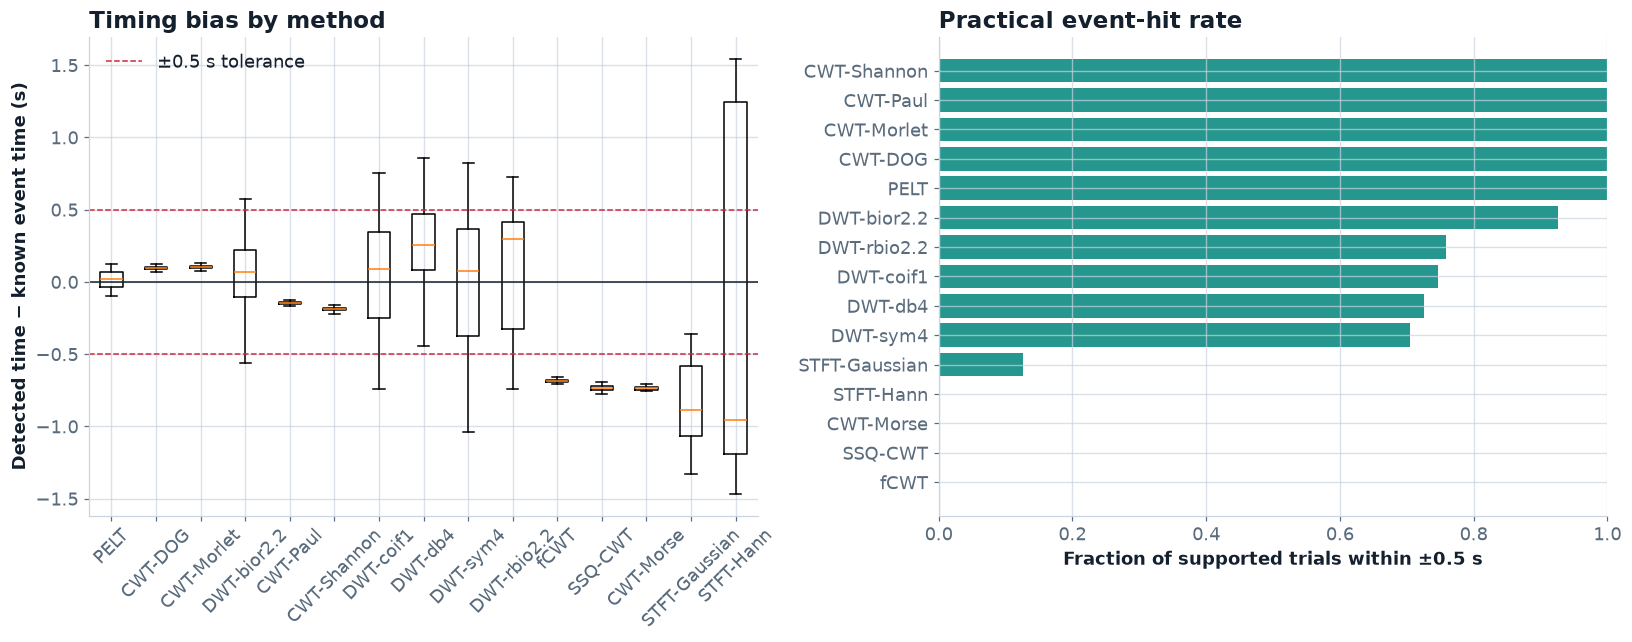

The hit-rate tolerance is a reporting choice for this benchmark, not a validated clinical cutoff.
Pointwise ROC AUC is omitted: adjacent time samples are autocorrelated and do not form independent cases.


In [48]:
figure, performance_axes = plt.subplots(1, 2, figsize=(15, 6))
error_plot_data = []
error_plot_labels = []
for method_name in method_performance_summary["method"]:
    method_errors = synthetic_supported_results.loc[
        synthetic_supported_results["method"] == method_name, "signed_offset_s"
    ].dropna().values
    if len(method_errors) > 0:
        error_plot_data.append(method_errors)
        error_plot_labels.append(method_name)

performance_axes[0].boxplot(error_plot_data, tick_labels=error_plot_labels, showfliers=False)
performance_axes[0].axhline(0.0, color=COLOUR_TEXT, linewidth=1)
performance_axes[0].axhline(TIMING_TOLERANCE_SECONDS[1], color=COLOUR_BASELINE,
                            linestyle="--", linewidth=1, label="±0.5 s tolerance")
performance_axes[0].axhline(-TIMING_TOLERANCE_SECONDS[1], color=COLOUR_BASELINE,
                            linestyle="--", linewidth=1)
performance_axes[0].set_ylabel("Detected time − known event time (s)")
performance_axes[0].set_title("Timing bias by method", loc="left")
performance_axes[0].tick_params(axis="x", labelrotation=45)
performance_axes[0].legend()

ordered_performance = method_performance_summary.sort_values("hit_rate_0_5_s", ascending=True)
performance_axes[1].barh(ordered_performance["method"], ordered_performance["hit_rate_0_5_s"],
                          color=COLOUR_WINNER, alpha=0.85)
performance_axes[1].set_xlim(0.0, 1.0)
performance_axes[1].set_xlabel("Fraction of supported trials within ±0.5 s")

performance_axes[1].set_title("Practical event-hit rate", loc="left")

plt.tight_layout()
plt.show()

print("The hit-rate tolerance is a reporting choice for this benchmark, not a validated clinical cutoff.")
print("Pointwise ROC AUC is omitted: adjacent time samples are autocorrelated and do not form independent cases.")


## 11. Paired statistics: Friedman, Wilcoxon, and a critical-difference diagram

Aggregating repeated trials within each scenario before comparing methods. A scenario is the paired block because every method sees the same scenario. Replicates are not counted as independent scenarios. The omnibus Friedman test is followed by paired Wilcoxon signed-rank tests against the predeclared STFT-Hann baseline with Holm family-wise adjustment.

An undetected event receives a declared 120-second penalty for ranking. Sampling-rejected trials are excluded for all methods together. This penalty is an operational benchmark choice, not a biological threshold.

In [49]:
from scipy.stats import friedmanchisquare, wilcoxon
from scipy.stats import studentized_range

candidate_statistical_methods = [
    "CWT-Morlet", "CWT-Paul", "CWT-DOG", "CWT-Shannon", "CWT-Morse",
    "fCWT", "SSQ-CWT", "STFT-Hann", "STFT-Gaussian", "DWT-db4",
    "DWT-sym4", "DWT-coif1", "DWT-bior2.2", "DWT-rbio2.2", "PELT",
]
minimum_scenario_coverage = max(3, int(np.ceil(0.80 * len(scenario_specs))))
method_scenario_coverage = operational_results.groupby("method")["scenario_id"].nunique()
PRIMARY_STATISTICAL_METHODS = [
    method_name for method_name in candidate_statistical_methods
    if method_scenario_coverage.get(method_name, 0) >= minimum_scenario_coverage
]
print("Methods meeting the predeclared 80% scenario-coverage rule:", PRIMARY_STATISTICAL_METHODS)
scenario_method_errors = operational_results[
    operational_results["method"].isin(PRIMARY_STATISTICAL_METHODS)
].groupby(["scenario_id", "method"])["rank_error_s"].mean().unstack()
complete_scenario_matrix = scenario_method_errors.dropna(axis=0, how="any")

print("Complete paired scenarios used for inference:", len(complete_scenario_matrix))
print("Methods in the predeclared statistical comparison:", list(complete_scenario_matrix.columns))

if len(complete_scenario_matrix) >= 3 and complete_scenario_matrix.shape[1] >= 3:
    friedman_result = friedmanchisquare(*[
        complete_scenario_matrix[method_name].to_numpy()
        for method_name in complete_scenario_matrix.columns
    ])
    print("Friedman chi-square:", round(float(friedman_result.statistic), 4))
    print("Friedman p-value   :", float(friedman_result.pvalue))
else:
    friedman_result = None
    print("Friedman test not calculated: too few complete scenario blocks or methods.")

paired_test_rows = []
reference_method = "STFT-Hann"


Methods meeting the predeclared 80% scenario-coverage rule: ['CWT-Morlet', 'CWT-Paul', 'CWT-DOG', 'CWT-Shannon', 'CWT-Morse', 'fCWT', 'SSQ-CWT', 'STFT-Hann', 'STFT-Gaussian', 'DWT-db4', 'DWT-sym4', 'DWT-coif1', 'DWT-bior2.2', 'DWT-rbio2.2', 'PELT']
Complete paired scenarios used for inference: 19
Methods in the predeclared statistical comparison: ['CWT-DOG', 'CWT-Morlet', 'CWT-Morse', 'CWT-Paul', 'CWT-Shannon', 'DWT-bior2.2', 'DWT-coif1', 'DWT-db4', 'DWT-rbio2.2', 'DWT-sym4', 'PELT', 'SSQ-CWT', 'STFT-Gaussian', 'STFT-Hann', 'fCWT']
Friedman chi-square: 254.6159
Friedman p-value   : 3.1874647032437896e-46


#### Continuing the calculation


In [50]:
if reference_method in complete_scenario_matrix.columns:
    raw_p_values = []
    compared_method_names = []
    for method_name in complete_scenario_matrix.columns:
        if method_name == reference_method:
            continue
        method_a_values = complete_scenario_matrix[method_name].to_numpy()
        method_b_values = complete_scenario_matrix[reference_method].to_numpy()
        if np.allclose(method_a_values, method_b_values):
            test_statistic = 0.0
            raw_p_value = 1.0
        else:
            wilcoxon_result = wilcoxon(method_a_values, method_b_values,
                                       alternative="two-sided", zero_method="wilcox",
                                       method="auto")
            test_statistic = float(wilcoxon_result.statistic)
            raw_p_value = float(wilcoxon_result.pvalue)
        paired_test_rows.append({
            "method": method_name,
            "reference": reference_method,
            "median_absolute_error_s": float(np.median(method_a_values)),
            "reference_median_absolute_error_s": float(np.median(method_b_values)),
            "wilcoxon_statistic": test_statistic,
            "p_raw": raw_p_value,
        })
        raw_p_values.append(raw_p_value)
        compared_method_names.append(method_name)

    sorted_p_order = np.argsort(raw_p_values)
    adjusted_values = np.empty(len(raw_p_values), dtype=float)
    running_adjusted_value = 0.0
    number_of_comparisons = len(raw_p_values)
    for sorted_position, original_position in enumerate(sorted_p_order):
        adjusted_candidate = (number_of_comparisons - sorted_position) * raw_p_values[original_position]
        running_adjusted_value = max(running_adjusted_value, adjusted_candidate)
        adjusted_values[original_position] = min(1.0, running_adjusted_value)

    for result_index, adjusted_value in enumerate(adjusted_values):
        paired_test_rows[result_index]["p_holm"] = float(adjusted_value)

paired_wilcoxon_table = pd.DataFrame(paired_test_rows)
if len(paired_wilcoxon_table) > 0:
    display(paired_wilcoxon_table.sort_values("p_holm").round(5))


,method,reference,median_absolute_error_s,reference_median_absolute_error_s,wilcoxon_statistic,p_raw,p_holm
0,CWT-DOG,STFT-Hann,0.09690,1.17128,0.0,0.00000,0.00005
1,CWT-Morlet,STFT-Hann,0.10274,1.17128,0.0,0.00000,0.00005
2,CWT-Morse,STFT-Hann,0.73822,1.17128,0.0,0.00000,0.00005
3,CWT-Paul,STFT-Hann,0.14517,1.17128,0.0,0.00000,0.00005
4,CWT-Shannon,STFT-Hann,0.18623,1.17128,0.0,0.00000,0.00005
5,DWT-bior2.2,STFT-Hann,0.19608,1.17128,0.0,0.00000,0.00005
6,DWT-coif1,STFT-Hann,0.32773,1.17128,0.0,0.00000,0.00005
7,DWT-db4,STFT-Hann,0.33870,1.17128,0.0,0.00000,0.00005
8,DWT-rbio2.2,STFT-Hann,0.40751,1.17128,0.0,0.00000,0.00005
9,DWT-sym4,STFT-Hann,0.36359,1.17128,0.0,0.00000,0.00005


#### Continuing the calculation


#### Drawing the rank comparison


In [51]:
def draw_critical_difference(mean_method_ranks, critical_difference, scenario_count):
    """Drawing readable mean ranks and groups within the Nemenyi critical difference."""
    ordered_names = list(mean_method_ranks.index)
    rank_values = mean_method_ranks.to_numpy()
    method_count = len(ordered_names)
    left_count = (method_count + 1) // 2
    figure, rank_axis = plt.subplots(figsize=(12, 6.5))
    rank_axis.set_xlim(-3.5, method_count + 4.5)
    rank_axis.set_ylim(-0.5 * left_count - 0.7, 2.0)
    rank_axis.axis("off")
    rank_axis.plot([1, method_count], [0, 0], color=COLOUR_TEXT)
    for rank_number in range(1, method_count + 1):
        rank_axis.plot([rank_number, rank_number], [-0.06, 0.06], color=COLOUR_TEXT)
        rank_axis.text(rank_number, 0.13, str(rank_number), ha="center", fontsize=9)
    for position, method_name in enumerate(ordered_names):
        mean_rank = rank_values[position]
        if position < left_count:
            label_height = -0.5 * (position + 1)
            label_edge, text_location, alignment = 0.65, -3.3, "left"
        else:
            label_height = -0.5 * (position - left_count + 1)
            label_edge, text_location, alignment = method_count + 0.35, method_count + 4.3, "right"
        rank_axis.plot([mean_rank, mean_rank, label_edge], [0, label_height, label_height],
                        color=COLOUR_MUTED, linewidth=0.9)
        rank_axis.text(text_location, label_height, f"{method_name}  ({mean_rank:.2f})",
                        ha=alignment, va="center", fontsize=10)
    group_height = 0.45
    previous_end = -1
    for start in range(method_count - 1):
        end = start
        while end + 1 < method_count and rank_values[end + 1] - rank_values[start] <= critical_difference:
            end += 1
        if end > start and end > previous_end:
            rank_axis.plot([rank_values[start], rank_values[end]], [group_height, group_height],
                            color=COLOUR_WINNER, linewidth=3, solid_capstyle="round")
            group_height += 0.16
            previous_end = end
    rank_axis.plot([1, 1 + critical_difference], [1.55, 1.55], color=COLOUR_BASELINE, linewidth=3)
    rank_axis.text(1, 1.72, f"CD = {critical_difference:.2f} | scenarios = {scenario_count}", fontsize=10)
    rank_axis.set_title("Mean ranks of penalized scenario-mean timing error (lower is better)", loc="left")
    figure.text(0.5, 0.015, "Connected rank groups differ by less than the Nemenyi CD; this does not establish equivalence.",
                 ha="center", fontsize=9)
    plt.tight_layout(rect=(0, 0.035, 1, 1))
    plt.show()


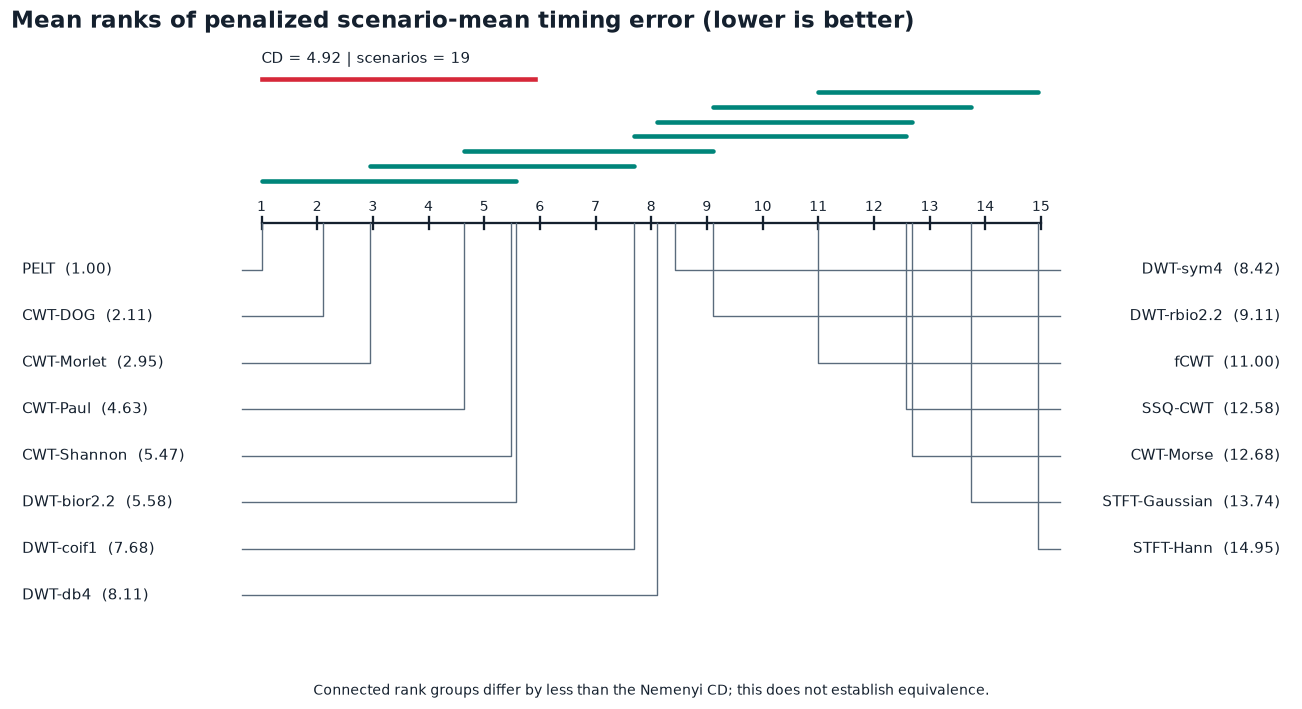

Mean ranks:


,mean_rank
method,
PELT,1.000
CWT-DOG,2.105
CWT-Morlet,2.947
CWT-Paul,4.632
CWT-Shannon,5.474
DWT-bior2.2,5.579
DWT-coif1,7.684
DWT-db4,8.105
DWT-sym4,8.421


The critical-difference display is descriptive post-hoc context; the paired table above reports Holm-adjusted Wilcoxon results.
Inference is conditional on these simulated scenarios; it does not establish clinical performance on Armstrong measurements.


In [52]:
if len(complete_scenario_matrix) >= 3 and complete_scenario_matrix.shape[1] >= 3:
    rank_matrix = complete_scenario_matrix.rank(axis=1, method="average", ascending=True)
    mean_method_ranks = rank_matrix.mean(axis=0).sort_values()
    number_of_scenarios = len(complete_scenario_matrix)
    number_of_methods = len(mean_method_ranks)
    nemenyi_q_value = studentized_range.ppf(0.95, number_of_methods, np.inf) / np.sqrt(2.0)
    critical_difference = nemenyi_q_value * np.sqrt(
        number_of_methods * (number_of_methods + 1.0) / (6.0 * number_of_scenarios)
    )

    draw_critical_difference(mean_method_ranks, critical_difference, number_of_scenarios)

    print("Mean ranks:")
    display(mean_method_ranks.rename("mean_rank").to_frame().round(3))
    print("The critical-difference display is descriptive post-hoc context; the paired table above reports Holm-adjusted Wilcoxon results.")
else:
    print("Critical-difference diagram not calculated because there are not enough complete paired scenarios.")

print("Inference is conditional on these simulated scenarios; it does not establish clinical performance on Armstrong measurements.")


## 12. Comparing timing accuracy with model-shape correlation

Checking directly whether a high Spearman association with λ(t) also corresponds to accurate event timing. This is the concrete check against selecting fCWT solely because its feature tracks the model state.

,median_abs_timing_error_s,median_lambda_shape_spearman,trial_count
method,,,
SSQ-CWT,0.7379,0.0954,95
CWT-Morse,0.7382,0.0898,95
CWT-Paul,0.1472,0.0721,95
DWT-sym4,0.3761,0.0601,95
DWT-db4,0.3594,0.0587,95
STFT-Hann,1.2038,0.0534,95
DWT-coif1,0.3345,0.0518,95
DWT-rbio2.2,0.4012,0.0475,95
DWT-bior2.2,0.1463,0.0473,95


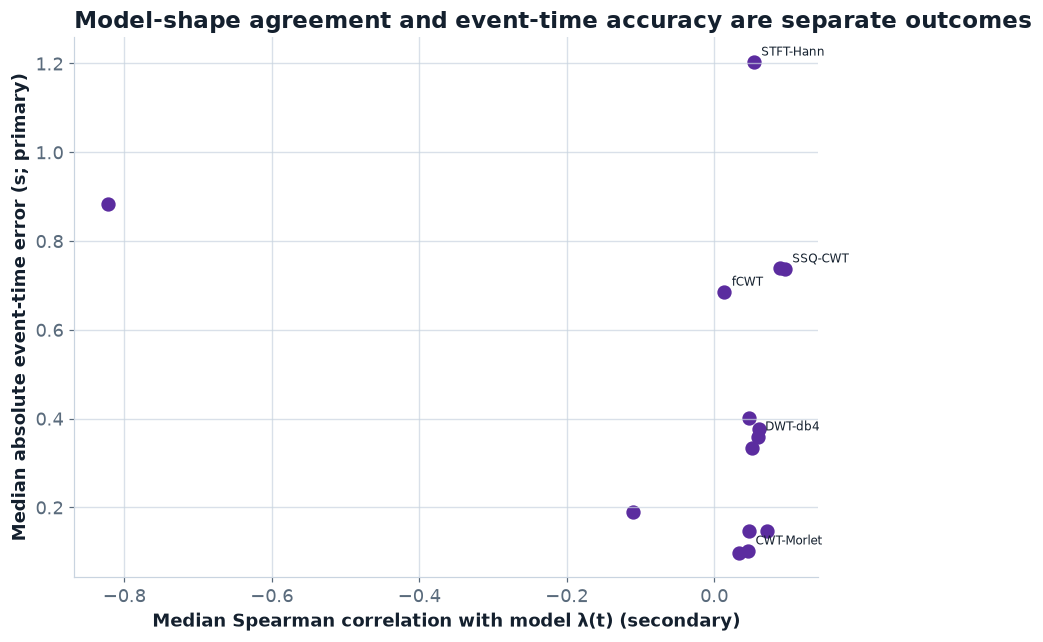

A method can correlate with the slow model state yet miss the command event, or detect the event without matching λ(t)'s full trajectory.


In [53]:
secondary_association_summary = synthetic_supported_results.groupby("method").agg(
    median_abs_timing_error_s=("absolute_offset_s", "median"),
    median_lambda_shape_spearman=("spearman_lambda_secondary", "median"),
    trial_count=("absolute_offset_s", "count"),
).dropna().sort_values("median_lambda_shape_spearman", ascending=False)

display(secondary_association_summary.round(4))

figure, association_axis = plt.subplots(figsize=(8, 6))
association_axis.scatter(
    secondary_association_summary["median_lambda_shape_spearman"],
    secondary_association_summary["median_abs_timing_error_s"],
    color=COLOUR_RUNNERUP,
    s=70,
)
labelled_methods = ["fCWT", "CWT-Morlet", "STFT-Hann", "DWT-db4", "PELT", "SSQ-CWT"]
for method_name, method_row in secondary_association_summary.loc[secondary_association_summary.index.isin(labelled_methods)].iterrows():
    association_axis.annotate(
        method_name,
        (method_row["median_lambda_shape_spearman"], method_row["median_abs_timing_error_s"]),
        xytext=(5, 4), textcoords="offset points", fontsize=8,
    )
association_axis.set_xlabel("Median Spearman correlation with model λ(t) (secondary)")
association_axis.set_ylabel("Median absolute event-time error (s; primary)")
association_axis.set_title("Model-shape agreement and event-time accuracy are separate outcomes", loc="left")
plt.tight_layout()
plt.show()

print("A method can correlate with the slow model state yet miss the command event, or detect the event without matching λ(t)'s full trajectory.")


## 13. Real-data conclusions and limits

Using the real Armstrong records to describe sampling support and observed stress responses. Because the workbooks do not provide independently labelled transient-onset or clot-time references, no supervised timing accuracy or real-data method winner is reported.

,workbook,measurements,median_samples,median_duration_s,median_equivalent_rate_hz,median_interval_cv,median_max_gap_ratio
0,data1.xlsx,3,65.0,63.0,16.303,2.039,151.375
1,data5.xlsx,9,65.0,63.0,16.303,2.039,151.376
2,data7.xlsx,5,65.0,63.0,16.302,2.039,151.375
3,data8.xlsx,9,65.0,63.0,16.302,2.039,151.373
4,data9.xlsx,27,65.0,63.0,16.302,2.039,151.375


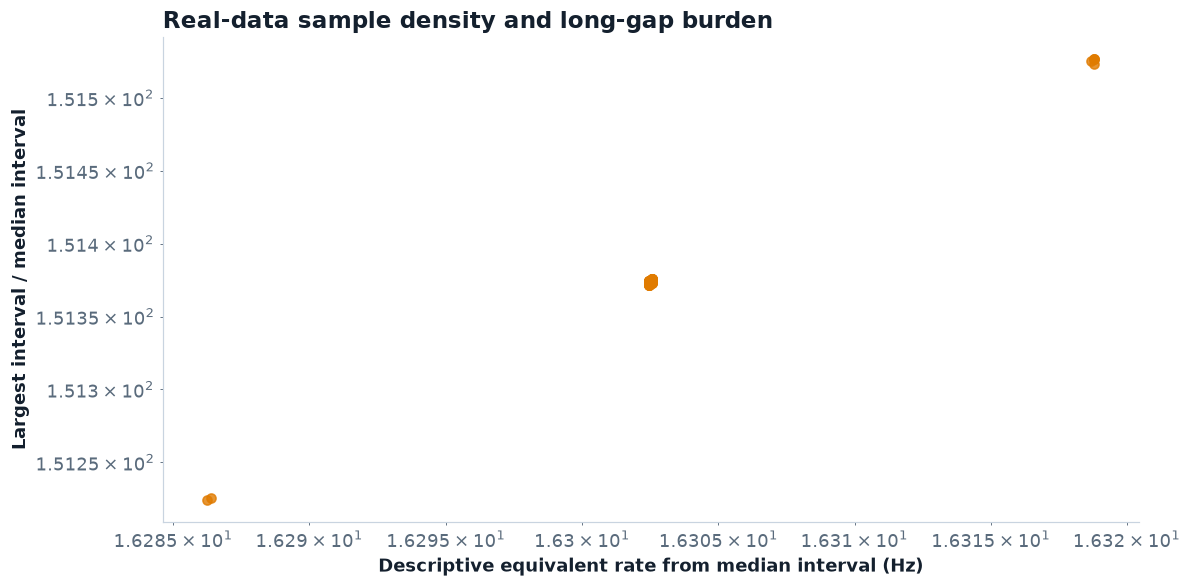

REAL-DATA CLAIM
The Armstrong workbooks support a descriptive analysis of stress responses and sampling quality.
They do not establish a gel point, clot time, or true physical transient time without independent labels.
The paper's λ(t) remains a model-derived secondary reference, not experimental ground truth.


In [54]:
if len(real_step_audit_table) > 0:
    audit_summary_by_workbook = real_step_audit_table.groupby("workbook").agg(
        measurements=("measurement_id", "count"),
        median_samples=("sample_count", "median"),
        median_duration_s=("duration_s", "median"),
        median_equivalent_rate_hz=("equivalent_rate_hz", "median"),
        median_interval_cv=("interval_cv", "median"),
        median_max_gap_ratio=("maximum_to_median_gap", "median"),
    ).reset_index()
    display(audit_summary_by_workbook.round(3))

    figure, real_axes = plt.subplots(figsize=(11, 5.5))
    real_axes.scatter(real_step_audit_table["equivalent_rate_hz"],
                      real_step_audit_table["maximum_to_median_gap"],
                      color=COLOUR_ACCENT, alpha=0.8)
    real_axes.set_xscale("log")
    real_axes.set_yscale("log")
    real_axes.set_xlabel("Descriptive equivalent rate from median interval (Hz)")
    real_axes.set_ylabel("Largest interval / median interval")
    real_axes.set_title("Real-data sample density and long-gap burden", loc="left")
    plt.tight_layout()
    plt.show()

print("REAL-DATA CLAIM")
print("The Armstrong workbooks support a descriptive analysis of stress responses and sampling quality.")
print("They do not establish a gel point, clot time, or true physical transient time without independent labels.")
print("The paper's λ(t) remains a model-derived secondary reference, not experimental ground truth.")


## 14. Analysis conclusions and reporting template

This final section records what the new analysis can answer and what evidence is still needed before making a biological claim.

### Concrete responses

1. **Sampling and preprocessing:** This version inspects timestamp intervals before any transform. It reports interval quantiles and gap ratios, avoids global 50 Hz upsampling, and rejects windows that would require crossing unsupported gaps. Baseline centring is used only where a pre-event interval is available; linear detrending is not the default because the relaxation trend may be the signal of interest.
2. **Timing accuracy:** Synthetic event time is set by the exact shear-rate command transition, with pre-event observations retained. The detector searches a full supported interval using an absolute, method-specific edge guard. The run summary reports event support and preserves failures rather than hiding them.
3. **Consistent comparison:** Every method sees the same synthetic run, the same sampled observations, a common requested physical frequency band with DWT’s approximate octave union reported, common baseline normalisation, and a shared event-time rule. STFT window duration and overlap, CWT frequency support, DWT octave levels, and transform edge support are recorded. The full-record FFT is explicitly treated as a spectral summary, not a timing detector.
4. **Validation:** Primary performance is measured against the known synthetic command time. Association with model λ(t) is reported separately as secondary shape agreement. Neither result alone demonstrates accurate clot-time detection in real blood.
5. **Statistics:** Repeated method results are paired within scenario. The Friedman test is the omnibus comparison; paired Wilcoxon tests use Holm adjustment. Replicate trials are summarized within scenarios before inference. The effective number of blocks is the number of complete scenarios, not the number of samples or method-trial rows.

### Claims to use in a report

- “The benchmark evaluates detection of a known shear-step event in paper-model-based synthetic stress traces under specified signal and sampling distortions.”
- “The real Armstrong measurements have no independent clot-time labels in the supplied workbooks, so real-data results are exploratory and cannot validate clot-time accuracy.”
- “The paper-derived structure parameter λ(t) is a model state. Agreement with λ(t) measures model-shape concordance, not direct detection of a physical clot point.”
- “A method is preferred only if it shows better paired event-time error and hit rate across held-out or predeclared scenarios, with acceptable support and runtime; no algorithm is assumed to win in advance.”

### Remaining evidence needed for a clinical claim

An independently measured event timestamp or reference assay, donor-specific model calibration, a prospectively defined acceptable timing tolerance, and validation on held-out real measurements are required before describing any result as clot-time accuracy or clinical utility.

## Saving reproducible results


In [55]:
synthetic_trial_manifest = pd.DataFrame([
    {"scenario_id": trial["scenario_id"], "replicate": trial["replicate"],
     "known_event_time_s": trial["event_time_s"], "recorded_sample_count": len(trial["time"]),
     "sampling_frequency_hz": trial["sampling_frequency_hz"],
     "measured_snr_db": trial["measured_snr_db"],
     "injected_harmonic_rms_ratio": trial["injected_harmonic_rms_ratio"]}
    for trial in synthetic_trials
])
result_tables = {
    "synthetic_trial_manifest.csv": synthetic_trial_manifest,
    "real_step_sampling_audit.csv": real_step_audit_table,
    "synthetic_scenarios.csv": synthetic_scenario_table,
    "synthetic_method_results.csv": synthetic_method_results,
    "method_performance_summary.csv": method_performance_summary,
    "paired_wilcoxon_holm.csv": paired_wilcoxon_table,
    "paired_scenario_error_matrix.csv": complete_scenario_matrix,
    "global_fft_summary.csv": synthetic_global_fft_summary,
}
for output_name, output_table in result_tables.items():
    output_table.to_csv(RESULTS_DIRECTORY / output_name, index=output_table.index.name is not None)

method_status_summary = synthetic_method_results.groupby(["method", "status"]).size().rename("row_count").reset_index()
method_status_summary.to_csv(RESULTS_DIRECTORY / "method_status_summary.csv", index=False)
display(method_status_summary)
print("Result tables saved to:", RESULTS_DIRECTORY)
print("Scenario count:", len(scenario_specs), "| Trial count:", len(synthetic_trials))
print("Real step-up measurements:", len(real_step_audit_table))
print("Paired scenario blocks:", len(complete_scenario_matrix))


,method,status,row_count
0,CWT-DOG,detected,95
1,CWT-DOG,unsupported sampling,5
2,CWT-Morlet,detected,95
3,CWT-Morlet,unsupported sampling,5
4,CWT-Morse,detected,95
5,CWT-Morse,unsupported sampling,5
6,CWT-Paul,detected,95
7,CWT-Paul,unsupported sampling,5
8,CWT-Shannon,detected,95
9,CWT-Shannon,unsupported sampling,5


Result tables saved to: /Users/riamishra/Desktop/Haemograph_Project/02_Synthetic_Benchmark/01_Model_Prototype/fresh_code_v2_results
Scenario count: 20 | Trial count: 100
Real step-up measurements: 53
Paired scenario blocks: 19


## Computed results from the completed execution

All 55 code cells completed successfully. The analysis audited 53 Armstrong step-up measurements and evaluated 20 synthetic scenarios with five repeats each. All 15 methods returned a timestamp on each of the 95 sampling-supported trials. The five trials with an intentionally missing event interval were rejected together for every method.

The exact synthetic input-step times varied independently from 57.037 to 62.985 seconds. Detection used fixed preprocessing, a fixed baseline, and signal-derived event selection. Known times were accessed afterward for scoring.

For this configured benchmark, **PELT** had the smallest mean absolute timing error (0.053 s; median 0.052 s). Among the spectral methods, **CWT-DOG** had the smallest mean error (0.097 s). These comparisons concern the chosen feature-and-detector pipelines on the generated stress responses. They do not establish clinical clot-time performance or a universal ordering of transforms.

The paired analysis used 19 complete scenario blocks. Friedman, paired Wilcoxon with Holm correction, and the Nemenyi rank display are computed above. The 2 Hz implementation check returned approximately 1.971 Hz for Paul, Morse, and SSQ-CWT, and the cached PELT loss matched the library's original L2 loss.

The supplied Armstrong workbooks have no independent clot-time labels. Their outputs remain sampling and response descriptions. Model-derived λ(t) correlation is a secondary shape-comparison result and does not determine the primary timing ranking.


## End of notebook

The original `fresh_code.ipynb` remains unchanged. This version carries forward its paper equation definitions, fixed parameter transcription, workbook parser, and solver foundation while replacing the timing target, preprocessing assumptions, comparison design, and inferential statistics.